# ViT 论文复现 （手搓 ViT）

在这个项目中，我们将**复现机器学习研究论文**并使用 PyTorch 从头开始创建 Vision Transformer (ViT)。

然后，我们将使用构建好的 ViT，在我们的 FoodVision Mini 数据集上完成图像分类任务。

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-applying-vit-to-food-vision-mini.png" alt="appyling the vision transformer architecture to FoodVision mini" width=900/>

## 温馨提示 : 

### 1. **这个项目所有的教程原创来自 : https://www.learnpytorch.io/ 你在此看到的只是我的学习笔记, 这个项目的内容可以精确定位到教程的第八部分: 08. PyTorch Paper Replicating, 对应网址 : https://www.learnpytorch.io/08_pytorch_paper_replicating/**

### 2. 如果你只想专注于 ViT 的构建，那么你可以选择性的掌握下面的某些部分即可（专注于模型构建）。 除此之外，如果你还对解整个图像分类的流程感兴趣，我建议你将每一部分认真的看完。不论哪一部分，看完以后尝试手动实现几次，直到不看任何教程，可以实现全部流程。

### 3. 这个项目的适合人群 : 有一定的 Python 基础、理解 ViT 的基本原理、了解深度学习或机器学习的图像分类问题。如果你看不懂 Python 代码或者还不了解 ViT 的基本原理，我建议你先不要阅读这个项目。这也不是一个从零开始解读 ViT 的项目。


## 什么是论文复现

机器学习正在快速发展，这已经不是什么秘密了。

其中许多进展都发表在机器学习研究论文中。

**论文复现**的目标是通过代码复现这些进展，以便你可以将这些技术用于你自己的任务。

例如，假设发布了一个新的模型架构，它在各种基准测试中的性能都优于之前的任何其他架构，那么在你自己的任务上尝试该架构不是很好吗？

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-what-is-paper-replicating-images-math-text-to-code.png" alt="paper replicating involves turning a machine learning reserch paper comprised of images/diagrams, text and math into usable code" width=1000/>

*机器学习论文复现涉及将由图像/图表、数学和文本组成的机器学习论文转化为可用代码，在我们的例子中，是可用的 PyTorch 代码。 [ViT 论文](https://arxiv.org/abs/2010.11929) 中的图表、数学方程式和文本。*

## 为什么要复现论文?

机器学习研究论文通常是将世界上一些最好的机器学习团队所做的几个月的工作和实验浓缩成几页文字的介绍。

如果这些实验在与你正在解决的问题相关的领域中取得更好的结果，那么对他们来说会很好。

此外，复现他人的工作是练习技能的绝佳方式。

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-george-hotz-quote.png" width=600 alt="george hotz quote saying to get better at being a machine learning engineer, download a paper, implement it and keep going until you have skills"/>

*George Hotz 是 [comma.ai](https://comma.ai/) 的创始人，这是一家自动驾驶汽车公司，在 [Twitch](https://www.twitch.tv/georgehotz) 上直播机器学习编码和 这些视频会完整发布到 [YouTube](https://www.youtube.com/c/georgehotzarchive)。 我从他的一个直播中摘录了这句话。 “٭”是要注意机器学习工程通常涉及预处理数据和使你的模型可供其他人使用（部署）的额外步骤。 *

当你第一次开始尝试复现研究论文时，你可能会不知所措，这很正常。

研究团队花费数周、数月甚至数年的时间来创作这些作品，所以如果你需要一些时间来阅读，更不用说复现这些作品了。

复现研究是一个非常棘手的问题，惊人的机器学习库和工具，例如 [HuggingFace](https://huggingface.co/)、[PyTorch Image Models](https://github.com/rwightman/pytorch-image-model)（`timm` 库）和 [fast.ai](https://www.fast.ai/) 的诞生是为了让机器学习研究更易于访问。

## 你可以从哪里获取代机器学习研究论文的代码样例

有几个地方可以找到和阅读机器学习研究论文（和代码）：

| **Resource** | **What is it?** |
| ----- | ----- |
| [arXiv](https://arxiv.org/) | arXiv 发音为“存档(archive)”，是一个免费和开放的资源，用于阅读从物理学到计算机科学（包括机器学习）的所有技术文章。| 
| [AK Twitter](https://twitter.com/ak92501) | AK Twitter 帐户发布机器学习研究亮点，通常几乎每天都有现场演示。 我不理解 9/10 的帖子，但我发现经常探索很有趣。 |
| [Papers with Code](https://paperswithcode.com/) | 精选的趋势、活跃和最伟大的机器学习论文的集合，其中许多包含附加的代码资源。 还包括一组常见的机器学习数据集、基准和当前最先进的模型。 |
| [lucidrains' `vit-pytorch` GitHub repository](https://github.com/lucidrains/vit-pytorch) |更少的地方可以找到研究论文，更多的是使用代码在更大规模和特定焦点上复现论文的示例。 `vit-pytorch` 存储库是来自使用 PyTorch 代码复现的各种研究论文的 Vision Transformer 模型架构的集合（此笔记本的大部分灵感来自此存储库）。 |

> **注意：** 此列表远非详尽无遗。 我只列出几个地方，我个人最常使用的地方。 所以要小心偏见。 但是，我注意到即使是这个简短的列表也常常无法满足我了解该领域正在发生的事情的需要。 再说了，我可能会发疯。

## 这个项目 (指的是 main.ipynb 这个文件) 包含了哪些部分

我们将复现机器学习研究论文 [*An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale*](https://arxiv.org/abs/2010.11929)（ViT 论文）。

Transformer 神经网络架构最初是在机器学习研究论文 [*Attention is all you need*](https://arxiv.org/abs/1706.03762) 中介绍的。

最初的 Transformer 架构设计用于处理一维 (1D) 文本序列。

**Transformer 架构** 通常被认为是任何使用 [**attention 机制**](https://en.wikipedia.org/wiki/Attention_(machine_learning)) 作为其主要学习层的神经网络。类似于卷积神经网络 (CNN) 如何使用卷积作为其主要学习层。

顾名思义，**Vision Transformer (ViT) 架构旨在使原始的 Transformer 架构适应视觉问题**。

最初的 Vision Transformer 在过去几年中经历了几次迭代，但是，我们将专注于复现原始版本，也就是所谓的“vanilla Vision Transformer”。因为如果你能重新创造原版，你就可以适应其他的。

我们将专注于按照原始 ViT 论文构建 ViT 架构并将其应用于 FoodVision Mini 图像分类任务。

| **主题** | **内容** |
| ----- | ----- |
| **[0. 环境准备](https://www.learnpytorch.io/08_pytorch_paper_replicating/#0-getting-setup)** | 配置基础环境 |
| **[1. 获取数据](https://www.learnpytorch.io/08_pytorch_paper_replicating/#1-get-data)** | 获取的披萨、牛排和寿司图像分类数据集|
| **[2. 创建 Dataset 和 DataLoader](https://www.learnpytorch.io/08_pytorch_paper_replicating/#2-create-datasets-and-dataloaders)** | 创建 DataLoader |
| **[3. 复现 ViT 论文：概览](https://www.learnpytorch.io/08_pytorch_paper_replicating/#3-replicating-the-vit-paper-an-overview)** | 复现机器学习研究论文可能颇具挑战。因此，在正式开始之前，我们先将 ViT 论文拆分为若干小部分，再逐一复现。 |
| **[4. 公式 1：图像块嵌入（ patch  Embedding）](https://www.learnpytorch.io/08_pytorch_paper_replicating/#4-equation-1-split-data-into-patches-and-creating-the-class-position-and-patch-embedding)** | ViT 架构主要由四个公式描述。第一个公式涉及图像块embedding和位置embedding，即将图像转换为一系列可学习的图像块表示。 |
| **[5. 公式 2：多头自注意力（MSA）](https://www.learnpytorch.io/08_pytorch_paper_replicating/#5-equation-2-multi-head-attention-msa)** | 自注意力和多头自注意力（MSA）机制是包括 ViT 在内的各类 Transformer 架构的核心。我们将使用 PyTorch 内置层创建一个 MSA 模块。 |
| **[6. 公式 3：多层感知机（MLP）](https://www.learnpytorch.io/08_pytorch_paper_replicating/#6-equation-3-multilayer-perceptron-mlp)** | ViT 架构在 Transformer 编码器和输出层中都使用了多层感知机。我们先为 Transformer 编码器创建一个 MLP。 |
| **[7. 创建 Transformer 编码器](https://www.learnpytorch.io/08_pytorch_paper_replicating/#7-create-the-transformer-encoder)** | Transformer 编码器通常由交替排列的 MSA 层（公式 2）和 MLP 层（公式 3）组成，并通过残差连接将它们连接起来。我们将组合第 5、6 节创建的模块，构建一个 Transformer 编码器。 |
| **[8. 整合所有组件，构建 ViT](https://www.learnpytorch.io/08_pytorch_paper_replicating/#8-putting-it-all-together-to-create-vit)** | 构建 ViT 架构所需的组件已经准备齐全。现在将它们整合到一个类中，作为我们可以直接调用的模型。 |
| **[9. 编写 ViT 模型的训练代码](https://www.learnpytorch.io/08_pytorch_paper_replicating/#9-setting-up-training-code-for-our-vit-model)** | 训练自行实现的 ViT，与训练此前其他模型的过程类似。借助 `train()` 函数，只需几行代码即可开始训练。 |
| **[10. 使用 `torchvision.models` 中的预训练 ViT](https://www.learnpytorch.io/08_pytorch_paper_replicating/#10-using-a-pretrained-vit-from-torchvisionmodels-on-the-same-dataset)** | 训练 ViT 这样的大型模型通常需要大量数据。由于我们只有少量披萨、牛排和寿司图片，因此将尝试通过迁移学习提升模型性能。 |
| **[11. 对自定义图片进行预测](https://www.learnpytorch.io/08_pytorch_paper_replicating/#11-make-predictions-on-a-custom-image)** | 机器学习的魅力在于看到模型能够处理你自己的数据。我们将使用表现最好的模型，对网络上随机下载的披萨/牛排/寿司进行预测。 |
> **注意：** 尽管我们将专注于复现 ViT 论文，但要避免过于拘泥于特定的论文，因为更新更好的方法通常会很快出现，所以技能应该是保持 好奇，同时建立将页面上的数学和单词转化为工作代码的基本技能。

## 在哪里可以获得帮助？

本课程的所有材料 [都可在 GitHub 上获取](https://github.com/mrdbourke/pytorch-deep-learning)。

如果你遇到麻烦，可以在课程的 [GitHub Discussions 页面](https://github.com/mrdbourke/pytorch-deep-learning/discussions) 上提问。

当然，还有 [PyTorch 文档](https://pytorch.org/docs/stable/index.html) 和 [PyTorch 开发者论坛](https://discuss.pytorch.org/)，这是一个对所有 PyTorch 相关事情都非常有帮助的地方。

## 0. 环境准备

首先确保我们已经获得了本节所需的所有模块。
 
主要包括 `torch` ,  `torchinfo` , `torchvision` , `matplotlib` 等


In [5]:
# 确保 torch 1.12+ 和 torchvision 0.13+  没有则下载
try:
    import torch
    import torchvision
    assert int(torch.__version__.split(".")[1]) >= 12 or int(torch.__version__.split(".")[0]) == 2, "torch version should be 1.12+"
    assert int(torchvision.__version__.split(".")[1]) >= 13, "torchvision version should be 0.13+"
    print(f"torch version: {torch.__version__}")
    print(f"torchvision version: {torchvision.__version__}")
except:
    print("[INFO] 正在安装兼容的 torch 和 torchvision；GPU 环境请参考 README。")
    %pip install -U torch torchvision
    import torch
    import torchvision
    print(f"torch version: {torch.__version__}")
    print(f"torchvision version: {torchvision.__version__}")

torch version: 2.9.1+cu126
torchvision version: 0.24.1+cu126


现在我们将继续常规导入，创建一些即将用到的方法 : 

* `set_seeds()` 设置随机种子, 当种子固定时，随机事件也会固定（这样多次实验结果都会相同，保证了可复现性）
* `download_data()` 下载给定链接的数据源
* `plot_loss_curves()` 来检查我们模型的训练结果


In [6]:
# 一些常规导入
import matplotlib.pyplot as plt
import torch
import torchvision

from torch import nn
from torchvision import transforms


try:
    from torchinfo import summary
except:
    print("[INFO] Couldn't find torchinfo... installing it.")
    %pip install -q torchinfo
    from torchinfo import summary


> **注意：** 在正式开始之前，最好确保你的设备上的 GPU 可以调用，这将加速整个训练过程，如果没有 GPU 也可以训练模型，但是速度会大打折扣。执行下面的代码，如果返回 'cuda' 即表示 GPU 可用。

In [7]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

## 1. 获取数据

由于我们继续使用 FoodVision Mini，让我们下载我们一直在使用的披萨、牛排和寿司图像数据集。

为此，我们可以使用我们在 [07. PyTorch Experiment Tracking 第 1 节](https://www.learnpytorch.io/07_pytorch_experiment_tracking/#1-get-data) 中创建的 `helper_functions.py` 中的 `download_data()` 函数。

我们将 `source` 设置为 [`pizza_steak_sushi.zip` 数据](https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip) 的原始 GitHub 链接，将 `destination` 设置为 `pizza_steak_sushi`。

In [8]:
# 从 GitHub 上下载数据集

from utils import download_data
image_path = download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                           destination="pizza_steak_sushi")
image_path

[INFO] 数据集已通过完整性检查：D:\project\image-classification-basics\data\pizza_steak_sushi
download_data 耗时: 0.44 秒


WindowsPath('D:/project/image-classification-basics/data/pizza_steak_sushi')

漂亮！数据已下载，让我们设置训练和测试目录。

In [9]:
# 设置训练集和测试集路径
from pathlib import Path
image_path = Path('./data/pizza_steak_sushi')
train_dir = image_path / "train"
test_dir = image_path / "test"

train_dir, test_dir

(WindowsPath('data/pizza_steak_sushi/train'),
 WindowsPath('data/pizza_steak_sushi/test'))

In [10]:
train_dir.is_dir(), test_dir.is_dir()

(True, True)

## 2. 创建 Datasets 和 DataLoaders

首先，我们将创建一个 transforms (manual_transforms) 来准备我们的图像。

这是 ViT 论文的第一个参考文献之一。

在表 3 中提到训练分辨率为 224（高度=224，宽度=224）。

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-image-size-and-batch-size.png" width=900 alt="Table 3 from the Vision Transformer paper showing the image size and batch size"/>

*你经常可以找到表格中列出的各种超参数设置。 在这种情况下，我们仍在准备数据，因此我们主要关注图像大小和批量大小等问题。 资料来源：[ViT 论文](https://arxiv.org/abs/2010.11929) 中的表 3。*

我们要确保我们的 transform 适当地调整图像大小。


### 2.1 为图像创建一个 transforms 

In [11]:
# 设置图像尺寸（来自 ViT 论文表 3）
IMG_SIZE = 224

# 手动创建图像预处理流程
manual_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])
print(f"Manually created transforms: {manual_transforms}")

Manually created transforms: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)


### 2.2 将数据放入 `DataLoader` 中

现在让我们创建我们的“DataLoader”。

ViT 论文指出使用的批量大小为 4096，是我们一直使用的批量大小 (32) 的 128 倍。

但是，我们将坚持使用 32 的批量大小。

因为某些硬件可能无法处理 4096 的批量大小。

批量大小为 4096 意味着一次需要将 4096 张图像放入 GPU 内存中。

当你有硬件来处理它时，这很有效，但是当你在单个 GPU 上运行时，首先确保事情以较小的批量大小能够正常工作是一个很好的选择。

该项目的扩展可能是尝试更高的批量值，看看会发生什么。
> **注意：** 我们在 `create_dataloaders()` 函数中使用 `pin_memory=True` 参数来加速计算。 `pin_memory=True` 通过“固定”以前见过的示例来避免 CPU 和 GPU 内存之间不必要的内存复现。 尽管使用更大的数据集大小可能会看到这样做的好处（我们的 FoodVision Mini 数据集非常小）。 然而，设置 `pin_memory=True` 并不会*总是*提高性能（这是我们在机器学习中的另一种情况，有些事情有时有效，有时无效），所以最好*实验，实验 ， 实验*。 请参阅 PyTorch [`torch.utils.data.DataLoader` 文档](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader) 或 [使深度学习从第一原理开始 Brrrr ](https://horace.io/brrr_intro.html) 作者 Horace He 了解更多信息。

In [12]:
# 设置批次大小
from dataset import create_dataloaders
BATCH_SIZE = 32 

# 创建数据加载器
train_dataloader, test_dataloader, class_names = create_dataloaders(
    train_dir=train_dir,
    test_dir=test_dir,
    transform=manual_transforms, # 使用手动创建的预处理流程
    batch_size=BATCH_SIZE,
    num_workers=0,          # 进程数量，数据加载速度与系统资源开销之间的权衡。由于我们的数据量较小， 0 就是可以了（代表一个主进程）
)

train_dataloader, test_dataloader, class_names

create_dataloaders 耗时: 0.05 秒


(<torch.utils.data.dataloader.DataLoader at 0x19ff1bc1400>,
 ['pizza', 'steak', 'sushi'])

### 2.3 可视化单个图像

现在我们已经加载了数据，让我们对其进行可视化！

ViT 论文中的一个重要步骤是将图像准备成 patch 

我们将在 [第 4 节]中了解这意味着什么，但现在，让我们查看单个图像及其标签。

为此，让我们从一批数据中获取单个图像和标签，并检查它们的形状。

In [13]:
# 获取一批图像
image_batch, label_batch = next(iter(train_dataloader))

# 从批次中取出一张图像
image, label = image_batch[0], label_batch[0]

# 查看图像和标签的形状
image.shape, label

(torch.Size([3, 224, 224]), tensor(1))

用 `matplotlib` 绘制图像及其标签。

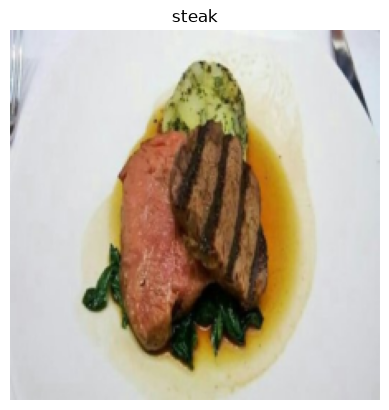

In [14]:
# 使用 matplotlib 绘制图像
plt.imshow(image.permute(1, 2, 0)) # 调整图像维度以适配 matplotlib：[color_channels, height, width] -> [height, width, color_channels]
plt.title(class_names[label])
plt.axis(False);

不错！

看起来我们的图像导入正确，让我们继续论文复现。

## 3. 复现 ViT 论文 : 概览

在我们编写更多代码之前，让我们讨论一下我们在做什么。

我们想针对我们自己的问题 FoodVision Mini 复现 ViT 论文。

所以我们的**模型输入**是：披萨、牛排和寿司的图像。

我们理想的**模型输出**是：披萨、牛排或寿司的预测标签。

问题是：我们如何从输入到期望的输出？

### 3.1 输入与输出 , 层与块

ViT 是一种深度学习神经网络架构。

任何神经网络架构通常都由**层layer**组成。

层的集合通常被称为**块block**。

将许多块堆叠在一起就为我们提供了整个架构。

**layer** 接受输入（例如图像张量），对其执行某种功能（例如，图层的 `forward()` 方法中的内容），然后返回输出。

因此，如果**单层**接受输入并给出输出，那么层的集合或**块**也会接受输入并给出输出。

让我们具体化：
* **Layer** - 接受输入，对其执行功能，返回输出。
* **Block** - 层的集合，接受输入，对其执行一系列功能，返回输出。
* **架构（或模型）** - 块的集合，接受输入，对其执行一系列功能，返回输出。

我们将使用这种意识形态来复现 ViT 论文。

我们将逐层、逐块、逐个功能地把拼图的各个部分拼在一起，就像乐高积木一样，得到我们想要的整体架构。

为了更好地理解，我们将对其进行分解，从单层的输入和输出开始，一直到整个模型的输入和输出。

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-intputs-outputs-layers-and-blocks.png" alt="inputs and outputs, layers and blocks of a model" width=900/>

*现代深度学习架构通常是层和块的集合。 层接受输入（数据作为数字表示）并使用某种函数（例如，上图中的自注意力公式，然而，这个函数几乎可以是任何东西）对其进行操作，然后将其输出。 块通常是相互叠加的层堆叠，与单层做类似的事情，但多次。*

### 3.2 具体来说：ViT 是由什么构成的？

整篇论文都有许多关于 ViT 模型的小细节。

找到它们就像一场大寻宝！

请记住，一篇研究论文通常是将几个月的工作压缩成几页纸，因此通过实践来复现它是可以理解的。

但是，我们将为架构设计寻找的主要三个资源是：
1. **图 1** - 这以图形方式给出了模型的概述，你几乎可以*仅使用此图重新创建架构。
2. **第 3.1 节中的四个方程** - 这些方程为图 1 中的彩色块提供了更多的数学基础。
3. **表 1** - 该表显示了不同 ViT 模型变体的各种超参数设置（例如层数和隐藏单元数）。 我们将专注于最小的版本，ViT-Base。

#### 3.2.1 图一

让我们从 ViT 论文的图 1 开始。

我们将关注的主要事项是：
1. **Layers** - 接受**输入**，对输入执行操作或功能，产生**输出**。
2. **Blocks** - 层的集合，反过来也接受一个**输入**并产生一个**输出**。

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-figure-1-inputs-and-outputs.png" width=900 alt="figure 1 from the original vision transformer paper"/>

*ViT 论文中的图 1 展示了创建架构的不同输入、输出、层和模块。我们的目标是使用 PyTorch 代码复现其中的每一个。*

ViT 架构由几个阶段组成：
* ** patch  + Position Embedding (inputs)** - 将输入图像转换为一系列图像 patch  ，并添加一个位置编号，即 patch  进入的顺序。
* **Linear projection of flattened patches (Embedded Patches)* - 图像 patch  变成了**embedding**，使用embedding而不只是图像值的好处是embedding是*可学习*表示（通常以向量的形式）可以通过训练改进的图像。
* **Norm** - 这是“[Layer Normalization](https://paperswithcode.com/method/layer-normalization)”或“LayerNorm”的缩写，一种用于正则化（减少过度拟合）神经网络的技术，你可以通过 PyTorch 层 [`torch.nn.LayerNorm()`](https://pytorch.org/docs/stable/generated/torch.nn.LayerNorm.html) 使用 LayerNorm。
* **Multi-Head Attention** - 这是一个[Multi-Headed Self-Attention layer](https://paperswithcode.com/method/multi-head-attention)或简称“MSA”。你可以通过 PyTorch 层 [`torch.nn.MultiheadAttention()`](https://pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html) 创建一个 MSA 层。
* **MLP（或 [多层感知器](https://en.wikipedia.org/wiki/Multilayer_perceptron)）** - MLP 通常可以指代任何前馈层的集合（或者在 PyTorch 的情况下，指层的集合使用 `forward()` 方法）。在 ViT 论文中，作者将 MLP 称为“MLP 块”，它包含两个 [`torch.nn.Linear()`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html) 层之间具有 [`torch.nn.GELU()`](https://pytorch.org/docs/stable/generated/torch.nn.GELU.html) 非线性激活（部分3.1) 和一个 [`torch.nn.Dropout()`](https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html) 层（附录 B.1）。
* **Transformer Encoder** - Transformer Encoder，是上面列出的层的集合。 Transformer 编码器内部有两个跳过连接（“+”符号），这意味着层的输入直接馈送到直接层以及后续层。整个 ViT 架构由多个堆叠在一起的 Transformer 编码器组成。
* **MLP Head** - 这是架构的输出层，它将输入的学习特征转换为类输出。由于我们正在研究图像分类，你也可以将其称为“分类器头”。 MLP Head 的结构类似于 MLP 块。

你可能会注意到，ViT 架构的许多部分都可以使用现有的 PyTorch 层创建。

这是因为 PyTorch 的设计方式，PyTorch 的主要目的之一是为研究人员和机器学习从业者创建可重用的神经网络层。

> **问题：** 为什么不从头开始编写所有代码？
>
> 你绝对可以通过使用自定义 PyTorch 层从论文中复现所有数学方程来做到这一点，这肯定是一种教育练习，但是，使用预先存在的 PyTorch 层通常是受欢迎的，因为预先存在的层经常经过广泛测试 并检查性能以确保它们运行正确且快速。

> **注意：** 我们将专注于编写 PyTorch 代码来创建这些层，对于这些层的作用的背景，我建议阅读完整的 ViT 论文或阅读每个层的链接资源 层。

让我们以图 1 为例，将其应用于我们的 FoodVision Mini 问题，即将食物图像分类为比萨、牛排或寿司。

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-figure-1-inputs-and-outputs-food-mini.png" width=900 alt="figure 1 from the original vision transformer paper adapted to work with food images, an image of pizza goes in and gets classified as 'pizza'"/>

*图 1 来自 ViT 论文，适用于 FoodVision Mini。 食物图像进入（比萨），图像变成 patch  ，然后投影到embedding。 然后embedding穿过各个层和块，并且（希望）返回“pizza”类。*

#### 3.2.2 四个公式（方程）

我们要查看的 ViT 论文的下一个主要部分是第 3.1 节中的四个方程。

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-four-equations.png" width=650 alt="four mathematical equations from the vision transformer machine learning paper"/>

*这四个方程式代表了 ViT 架构的四个主要部分背后的数学。*


| **编号** | **ViT 论文中 3.1 的描述** | 
| ----- | ----- | 
| 1 | ...Transformer 在其所有层中使用恒定的潜在向量大小 $D$ ，因此我们使用**可训练的线性投影**（方程式 1）将 patch  展平并映射到 $D$ 维度。 我们将此投影的输出称为 ** patch  embeddings**...**Position embeddings** 添加到 patch embeddings 以保留位置信息。 我们使用标准的**可学习的一维位置embedding**...|
| 2 | Transformer 编码器（Vaswani 等人，2017）由多头自注意力（MSA，见附录 A）和 MLP 块（等式 2、3）的交替层组成。 **Layernorm (LN) 在每个区块之前应用**，**在每个区块之后应用剩余residual连接**（Wang et al., 2019; Baevski & Auli, 2019）。|
| 3 | 与等式 2 相同. |
| 4 | 与 BERT 的 [ class ] 标记类似，我们**在embedding patch  序列中添加可学习的embedding** $\left(\mathbf{z}_{0}^{0}=\mathbf{x}_{\text {class }}\right)$，其在 Transformer 编码器输出的状态 $\left(\mathbf{z}_{L}^{0}\right)$ 用作图像表示 $\mathbf{y} $（等式 4）... |

让我们将这些描述映射到图 1 中的 ViT 架构。

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-mapping-the-four-equations-to-figure-1.png" width=1000 alt="mapping the vision transformer paper figure 1 to the four equations listed in the paper"/>

*将 ViT 论文中的图 1 与第 3.1 节中描述每个层/块背后的数学的四个方程联系起来。*

上图中发生了很多事情，但沿着彩色线条和箭头显示了 ViT 架构的主要概念。

我们如何进一步分解每个方程（我们的目标是用代码重新创建这些方程）？

在所有方程中（方程 4 除外），“$\mathbf{z}$”是特定层的原始输出：

1. $\mathbf{z}_{0}$ 是“z 零”（这是初始 patch  embedding层的输出）。
2. $\mathbf{z}_{\ell}^{\prime}$ 是“特定层的 z *prime*”（或 z 的中间值）。
3. $\mathbf{z}_{\ell}$ 是“特定层的z”。

$\mathbf{y}$ 是架构的整体输出。

#### 3.2.3 公式一总览

$$
\begin{aligned}
\mathbf{z}_{0} &=\left[\mathbf{x}_{\text {class }} ; \mathbf{x}_{p}^{1} \mathbf{E} ; \mathbf{x}_{p}^{2} \mathbf{E} ; \cdots ; \mathbf{x}_{p}^{N} \mathbf{E}\right]+\mathbf{E}_{\text {pos }}, & & \mathbf{E} \in \mathbb{R}^{\left(P^{2} \cdot C\right) \times D}, \mathbf{E}_{\text {pos }} \in \mathbb{R}^{(N+1) \times D}
\end{aligned}
$$

这个等式处理输入图像的类标记、 patch  embedding和位置嵌入（$\mathbf{E}$ 用于embedding）。

在向量形式中，embedding可能类似于：

```python
x_input = [class_token, image_patch_1, image_patch_2, image_patch_3...] + [class_token_position, image_patch_1_position, image_patch_2_position, image_patch_3_position...]
```

向量中的每个元素都是可学习的（它们的 `requires_grad=True`）。

#### 3.2.4 公式二总览


$$
\begin{aligned}
\mathbf{z}_{\ell}^{\prime} &=\operatorname{MSA}\left(\operatorname{LN}\left(\mathbf{z}_{\ell-1}\right)\right)+\mathbf{z}_{\ell-1}, & & \ell=1 \ldots L
\end{aligned}
$$

这表示对于从 $1$ 到 $L$（总层数）的每一层，都有一个包裹 LayerNorm 层 (LN) 的多头注意力层 (MSA)。

最后的加法相当于把输入加到输出中，形成一个[skip/residual connection](https://paperswithcode.com/method/residual-connection)。

我们将此层称为“MSA 块”。

在伪代码中，这可能如下所示：
```python
x_output_MSA_block = MSA_layer(LN_layer(x_input)) + x_input
```

注意最后的跳过连接（将层的输入添加到层的输出）。

#### 3.2.5 公式三总览


$$
\begin{aligned}
\mathbf{z}_{\ell} &=\operatorname{MLP}\left(\operatorname{LN}\left(\mathbf{z}_{\ell}^{\prime}\right)\right)+\mathbf{z}_{\ell}^{\prime}, & & \ell=1 \ldots L \\
\end{aligned}
$$

这表示对于从 $1$ 到 $L$（总层数）的每一层，还有一个多层感知器层 (MLP) 包装了一个 LayerNorm 层 (LN)。

最后的添加显示了跳过/剩余连接的存在。

我们将此层称为“MLP 块”。

在伪代码中，这可能如下所示：
```python
x_output_MLP_block = MLP_layer(LN_layer(x_output_MSA_block)) + x_output_MSA_block
```

注意最后的跳过连接（将层的输入添加到层的输出）。

#### 3.2.6 公式四总览

$$
\begin{aligned}
\mathbf{y} &=\operatorname{LN}\left(\mathbf{z}_{L}^{0}\right) & &
\end{aligned}
$$

这表示对于最后一层 $L$，输出 $y$ 是包裹在 LayerNorm 层 (LN) 中的 $z$ 的 0 索引标记。

或者在我们的例子中，`x_output_MLP_block` 的 0 索引：

```python
y = LN_layer(Linear_layer(x_output_MLP_block[0]))
```

当然，上面有一些简化，但是当我们开始为每个部分编写 PyTorch 代码时，我们会处理这些简化。

> **注意：**以上部分涵盖了很多信息。 但是不要忘记，如果某些事情你不理解，你可以随时进一步研究。 通过提出诸如“什么是残差连接？”之类的问题。

#### 3.2.7 表一

我们将（目前）关注的 ViT 架构难题的最后一块是表 1。

| Model | Layers | Hidden size $D$ | MLP size | Heads | Params |
| :--- | :---: | :---: | :---: | :---: | :---: |
| ViT-Base | 12 | 768 | 3072 | 12 | $86M$ |
| ViT-Large | 24 | 1024 | 4096 | 16 | $307M$ |
| ViT-Huge | 32 | 1280 | 5120 | 16 | $632M$ |

<div align=center>
    <i>Table 1: Details of Vision Transformer model variants. Source: <a href="https://arxiv.org/abs/2010.11929">ViT paper</a>.</i>
</div>
<br>

该表展示了每个 ViT 架构的各种超参数。

你可以看到数字从 ViT-Base 逐渐增加到 ViT-Huge。

我们将专注于复现 ViT-Base（从小处着手并在必要时扩大规模），但我们将编写可以轻松扩大到更大变体的代码。

分解超参数：
* **Layers** - 有多少个 Transformer Encoder 块？ （每个都包含一个 MSA 块和 MLP 块）
* **Hidden size $D$** - 这是整个架构中的embedding维度，这将是我们的图像在修补和embedding时变成的向量的大小。一般来说，embedding维度越大，可以捕获的信息越多，结果就越好。然而，更大的embedding是以更多计算为代价的。
* **MLP 大小** - MLP 层中隐藏单元的数量是多少？
* **Heads** - 多头注意力层中有多少个头？
* **Params** - 模型的参数总数是多少？通常，更多的参数会带来更好的性能，但代价是更多的计算。你会注意到，甚至 ViT-Base 的参数也远远超过我们迄今为止使用的任何其他模型。

我们将使用这些值作为 ViT 架构的超参数设置。

## 4. 公式 1 : 图像块嵌入( patch  Embedding)

我记得我的一位机器学习工程师朋友曾经说过“这都是关于嵌入(embedding)的”。

例如，如果你可以以一种好的、可学习的方式表示你的数据（因为**embedding是可学习的表示**），那么学习算法很可能能够在它们上表现良好。

话虽如此，让我们从为 ViT 架构创建类、位置和 patch embedding 开始。

我们将从** patch  embedding**开始。

这意味着我们将把输入图像转换成一系列 patch，然后embedding这些 patch 。

回想一下，**embedding**是某种形式的可学习表示，并且通常是一个向量。

可学习一词很重要，因为这意味着输入图像（模型看到的）的数字表示可以随着时间的推移而得到改进。

我们将从 ViT 论文（粗体）第 3.1 节的开头段落开始：

> 标准 Transformer 接收一维tokenembedding序列作为输入。 为了处理 2D 图像，我们将图像 $\mathbf{x} \in \mathbb{R}^{H \times W \times C}$ 重塑为一系列扁平化的 2D patch  $\mathbf{x}_{p} \in \mathbb{R}^{N \times\left(P^{2} \cdot C\right)}$，其中$(H, W)$是原始图像的分辨率，$C$是 通道数，$(P, P)$ 是每个图像块的分辨率，$N=H W / P^{2}$ 是生成的块数，它也作为 Transformer 的有效输入序列长度 . Transformer 在其所有层中使用恒定的潜在向量大小 $D$，因此我们将 patch  展平并使用可训练的线性投影映射到 $D$ 维度（方程式 1）。 我们将此投影的输出称为 ** patch  embeddings**。

以及我们处理图像形状的大小，让我们记住 ViT 论文表 3 中的行：

> 训练分辨率为 **224**。

让我们分解上面的文字。

* $D$ 是 ** patch  embeddings** 的大小，对于不同大小的 ViT 模型，$D$ 的不同值可以在表 1 中找到。
* 图像以 2D 开始，大小为 ${H \times W \times C}$。
     * $(H, W)$ 是原始图像的分辨率（高度，宽度）。
     * $C$ 是通道数。
* 图像被转换为大小为 ${N \times\left(P^{2} \cdot C\right)}$ 的扁平 2D patch 序列。
     * $(P, P)$ 是每个图像 patch  的分辨率（** patch  大小**）。
     * $N=H W / P^{2}$ 是生成的 patch  数，它也用作 Transformer 的输入序列长度。

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-equation-1-annotated.png" width=900 alt="mapping the vit architecture diagram positional and patch embeddings portion to the relative mathematical equation describing what's going on"/>

*将 ViT 架构的 patch  和位置embedding部分从图 1 映射到公式 1。第 3.1 节的开头段落描述了 patch  embedding层的不同输入和输出形状。*

### 4.1 计算 patch embedding 输入和输出的形状

让我们创建一些变量来模仿上面的每个术语（例如 $H$、$W$ 等）。

我们将使用 16 的 patch  大小 ($P$)，因为它是 ViT-Base 使用的最佳性能版本（有关更多信息，请参见 ViT 论文中表 5 的“ViT-B/16”列）。

In [15]:
# 创建示例参数
height = 224 # H（训练分辨率为 224）
width = 224 # 宽度 W
color_channels = 3 # 颜色通道数 C
patch_size = 16 # patch 边长 P

# 计算 N（patch 数量）
number_of_patches = int((height * width) / patch_size**2)
print(f"Number of patches (N) with image height (H={height}), width (W={width}) and patch size (P={patch_size}): {number_of_patches}")

Number of patches (N) with image height (H=224), width (W=224) and patch size (P=16): 196


我们已经有了 patch  的数量，我们如何创建图像输出大小呢？

更好的是，让我们复现 patch  embedding层的输入和输出形状。

记起：

* **输入：** 图像以 2D 开头，大小为 ${H \times W \times C}$。
* **输出：** 图像被转换为大小为 ${N \times\left(P^{2} \cdot C\right)}$ 的扁平 2D patch 序列。

In [16]:
# 输入形状（单张图像的尺寸）
embedding_layer_input_shape = (height, width, color_channels)

# 输出形状
embedding_layer_output_shape = (number_of_patches, patch_size**2 * color_channels)

print(f"Input shape (single 2D image): {embedding_layer_input_shape}")
print(f"Output shape (single 2D image flattened into patches): {embedding_layer_output_shape}")

Input shape (single 2D image): (224, 224, 3)
Output shape (single 2D image flattened into patches): (196, 768)


获得输入和输出形状！

### 4.2 将单张图片转换为 patches

现在我们知道了 ** patch embedding** 层的理想输入和输出形状，让我们开始制作它。

我们正在做的是将整个架构分解成更小的部分，专注于各个层的输入和输出。

那么我们如何创建 patch embedding层呢？

我们很快就会谈到这一点，首先，让我们可视化！将图像变成 patch 的样子。

让我们从我们的单个图像开始。

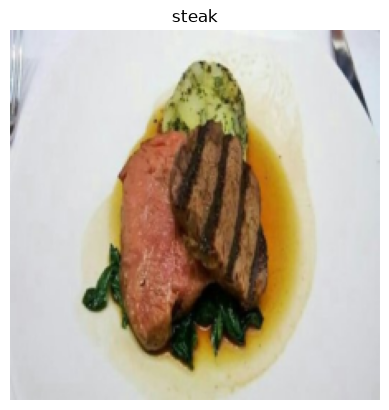

In [17]:
# 查看单张图像
plt.imshow(image.permute(1, 2, 0)) # 调整维度以适配 matplotlib
plt.title(class_names[label])
plt.axis(False);

我们希望将这个图像变成与 ViT 论文的图 1 一致的自身 patch  。

我们如何从可视化顶行的修补像素开始？

我们可以通过索引不同的图像尺寸来做到这一点。

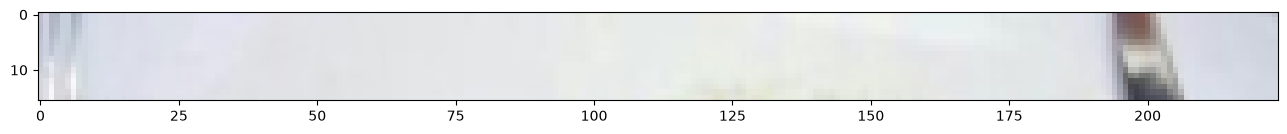

In [18]:
# 调整图像形状以适配 matplotlib：(color_channels, height, width) -> (height, width, color_channels)
image_permuted = image.permute(1, 2, 0)

# 通过索引绘制最上方一行的 patch 像素
patch_size = 16
plt.figure(figsize=(patch_size, patch_size))
plt.imshow(image_permuted[:patch_size, :, :]);

现在我们得到了第一行，让我们把它变成 patch  。

我们可以通过迭代顶行中的 patch 数量来做到这一点。

Number of patches per row: 14.0
 patch  size: 16 pixels x 16 pixels


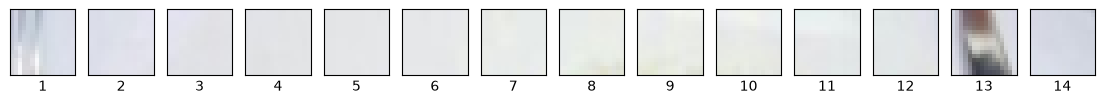

In [19]:
# 设置超参数，并确保 img_size 能被 patch_size 整除
img_size = 224
patch_size = 16
num_patches = img_size/patch_size
assert img_size % patch_size == 0, "Image size must be divisible by patch size"
print(f"Number of patches per row: {num_patches}\n patch  size: {patch_size} pixels x {patch_size} pixels")

# 创建一组子图
fig, axs = plt.subplots(nrows=1,
                        ncols=img_size // patch_size, # 每个 patch 对应一列
                        figsize=(num_patches, num_patches),
                        sharex=True,
                        sharey=True)

# 遍历最上方一行的 patch
for i, patch in enumerate(range(0, img_size, patch_size)):
    axs[i].imshow(image_permuted[:patch_size, patch:patch+patch_size, :]); # 保持高度索引不变，改变宽度索引
    axs[i].set_xlabel(i+1) # 设置标签
    axs[i].set_xticks([])
    axs[i].set_yticks([])

这些是一些好看的 patch  ！
我们如何为整个图像做呢？
这次我们将遍历高度和宽度的索引，并将每个 patch  绘制为自己的子图。

Number of patches per row: 14.0        
Number of patches per column: 14.0        
Total patches: 196.0        
patch size: 16 pixels x 16 pixels


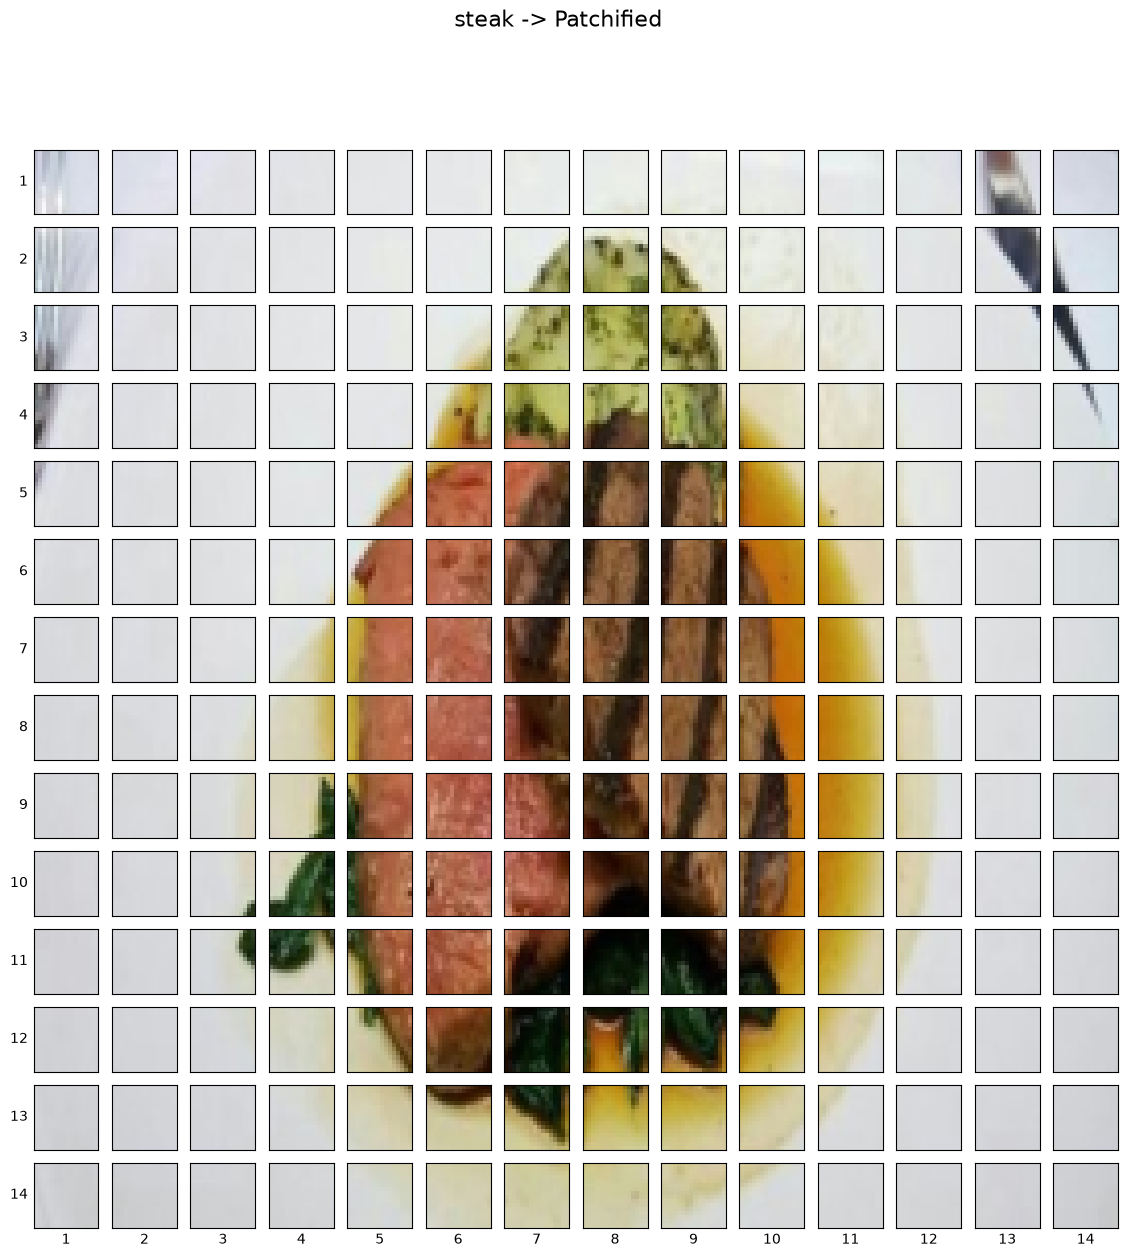

In [20]:
# 设置超参数，并确保 img_size 能被 patch_size 整除
img_size = 224
patch_size = 16
num_patches = img_size/patch_size
assert img_size % patch_size == 0, "Image size must be divisible bypatchsize"
print(f"Number of patches per row: {num_patches}\
        \nNumber of patches per column: {num_patches}\
        \nTotal patches: {num_patches*num_patches}\
        \npatch size: {patch_size} pixels x {patch_size} pixels")

# 创建一组子图
fig, axs = plt.subplots(nrows=img_size // patch_size, # 子图行数需要整数，不能使用浮点数
                        ncols=img_size // patch_size,
                        figsize=(num_patches, num_patches),
                        sharex=True,
                        sharey=True)

# 遍历图像的高度和宽度
for i, patch_height in enumerate(range(0, img_size, patch_size)): # 遍历高度
    for j, patch_width in enumerate(range(0, img_size, patch_size)): # 遍历宽度

        # 绘制调整维度后的图像 patch，image_permuted 的维度为（高度、宽度、颜色通道）
        axs[i, j].imshow(image_permuted[patch_height:patch_height+patch_size, # 遍历高度
                                  patch_width:patch_width+patch_size, # 遍历宽度
                                        :]) # 获取全部颜色通道

        # 设置标签并隐藏刻度，仅保留外侧标签以使图像更清晰
        axs[i, j].set_ylabel(i+1,
                             rotation="horizontal",
                             horizontalalignment="right",
                             verticalalignment="center")
        axs[i, j].set_xlabel(j+1)
        axs[i, j].set_xticks([])
        axs[i, j].set_yticks([])
        axs[i, j].label_outer()

# 设置整幅图的标题
fig.suptitle(f"{class_names[label]} -> Patchified", fontsize=16)
plt.show()

现在我们如何将这些 patch  中的每一个转换为embedding并将它们转换为序列？

提示：我们可以使用 PyTorch 层。 你能猜到是哪个吗？

### 4.3 使用 `torch.nn.Conv2d()` 创建图像 patchs

我们已经看到图像变成 patch  后的样子，现在让我们开始使用 PyTorch 复现 patch  embedding层。

为了可视化我们的单个图像，我们编写了代码来循环遍历单个图像的不同高度和宽度尺寸并绘制单独的 patch  。

这个操作与我们在 [03.3] 中看到的卷积操作非常相似。 PyTorch 计算机视觉第 7.1 节：逐步执行[`nn.Conv2d()`](https://www.learnpytorch.io/03_pytorch_computer_vision/#71-stepping-through-nnconv2d)。

事实上，ViT 论文的作者在第 3.1 节中提到， patch  embedding可以通过卷积神经网络 (CNN) 实现：

> **混合架构。** 作为原始图像块的替代方案，输入序列可以由 CNN 的特征图形成（LeCun 等人，1989 年）。 在这个混合模型中， patch  embedding投影 $\mathbf{E}$（等式 1）应用于从 **CNN 特征图**中提取的 patch  。 作为一种特殊情况， patch  的空间大小可以是 $1\times 1$，这意味着**输入序列是通过简单地展平特征图的空间维度并投影到 Transformer 维度得到的**。 如上所述添加分类输入embedding和位置embedding。

他们所指的“**特征图**”是通过给定图像的卷积层产生的权重/激活。

<img src="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/images/08-vit-paper-patch-embedding-animation.gif" width=900 alt="example of creating a patch embedding by passing a convolutional layer over a single image"/>

*通过设置 [`torch.nn.Conv2d()`](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) 层的 `kernel_size` 和 `stride` 参数等于 `patch_size`，我们可以有效地得到一个层，将我们的图像分割成 patch  ，并为每个 patch  创建一个可学习的嵌入（在 ViT 论文中称为“线性投影”）。*

还记得我们用于 patch  embedding层的理想输入和输出形状吗？

* **输入：** 图像以 2D 开头，大小为 ${H \times W \times C}$。
* **输出：** 图像被转换为大小为 ${N \times\left(P^{2} \cdot C\right)}$ 的扁平 2D patch 的 1D 序列。

或者对于 224 的图像大小和 16 的 patch  大小：

* **输入（二维图像）：**（224、224、3）->（高度、宽度、颜色通道）
* **输出（扁平的 2D patch ）：** (196, 768) ->（ patch  数量，embedding维度）

我们可以通过以下方式重新创建这些：
* [`torch.nn.Conv2d()`](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) for turning our image into patches of CNN feature maps.
* [`torch.nn.Flatten()`](https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html) for flattening the spatial dimensions of the feature map.

让我们从 `torch.nn.Conv2d()` 层开始。

我们可以通过将 `kernel_size` 和 `stride` 设置为 `patch_size` 来复现 patch  的创建。

这意味着每个卷积核的大小将是 `(patch_size x patch_size)` 或者如果 `patch_size=16`, `(16 x 16)` （相当于一个完整的 patch  ）。

并且卷积核的每一步或 `stride`将是`patch_size`像素长或`16`像素长（相当于步进到下一个 patch  ）。

我们将为图像中的颜色通道数设置`in_channels=3`，我们将设置`out_channels=768`，与表 1 中 ViT-Base 的 $D$ 值相同（这是embedding维度 ，每个图像将被embedding到一个大小为 768 的可学习向量中）。

In [21]:
from torch import nn

# 设置 patch 大小
patch_size=16

# 使用 ViT 论文中的超参数创建 Conv2d 层
conv2d = nn.Conv2d(in_channels=3, # 颜色通道数
                   out_channels=768, # 来自表 1 的隐藏维度 D，也就是 embedding 维度
                   kernel_size=patch_size, # 也可以使用 (patch_size, patch_size)
                   stride=patch_size,
                   padding=0)

现在我们有了一个卷积层，让我们看看当我们通过它传递单个图像时会发生什么。

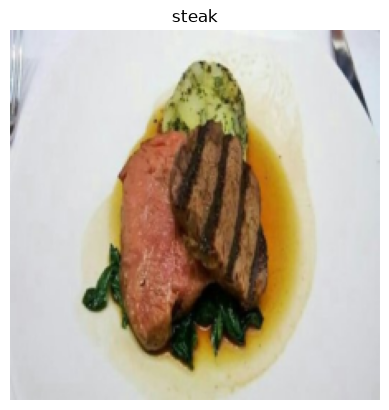

In [22]:
# 查看单张图像
plt.imshow(image.permute(1, 2, 0)) # 调整维度以适配 matplotlib
plt.title(class_names[label])
plt.axis(False);

In [23]:
# 将图像输入卷积层
image_out_of_conv = conv2d(image.unsqueeze(0)) # 添加批次维度：(color_channels, height, width) -> (batch, color_channels, height, width)
print(image_out_of_conv.shape)

torch.Size([1, 768, 14, 14])


将我们的图像通过卷积层将其变成一系列 768 个（这是embedding大小或 $D$）特征/激活图。

所以它的输出形状可以读作：
    
```python
torch.Size([1, 768, 14, 14]) -> [batch_size, embedding_dim, feature_map_height, feature_map_width]
```

让我们可视化五个随机特征图，看看它们长什么样。

Showing random convolutional feature maps from indexes: [576, 216, 380, 486, 254]


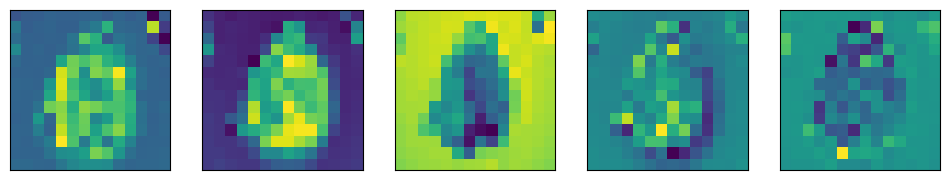

In [24]:
# 随机绘制 5 张卷积特征图
import random
random_indexes = random.sample(range(0, 758), k=5) # 从 embedding 通道索引中随机选取 5 个
print(f"Showing random convolutional feature maps from indexes: {random_indexes}")

# 创建图表
fig, axs = plt.subplots(nrows=1, ncols=5, figsize=(12, 12))

# 绘制随机选取的图像特征图
for i, idx in enumerate(random_indexes):
    image_conv_feature_map = image_out_of_conv[:, idx, :, :] # 按通道索引获取卷积层输出张量中的特征图
    axs[i].imshow(image_conv_feature_map.squeeze().detach().numpy())
    axs[i].set(xticklabels=[], yticklabels=[], xticks=[], yticks=[]);

注意特征图是如何代表原始图像的，在可视化更多之后，你可以开始看到不同的主要轮廓和一些主要特征。

需要注意的重要一点是，随着神经网络的学习，这些特征可能会随着时间而改变。

正因为如此，这些特征图可以被认为是我们图像的**可学习embedding**。

让我们以数字形式检查一个。

In [25]:
# 获取张量形式的单张特征图
single_feature_map = image_out_of_conv[:, 0, :, :]
single_feature_map, single_feature_map.requires_grad

(tensor([[[ 1.2983e-02, -3.6620e-02, -3.9085e-02, -3.6774e-02, -3.4839e-02,
           -3.5100e-02, -2.7635e-02, -2.7419e-02, -2.4803e-02, -2.7444e-02,
           -3.6623e-02, -3.0652e-02,  1.4024e-04, -3.8495e-02],
          [-3.5732e-02, -3.7657e-02, -3.3283e-02, -3.3575e-02, -3.6595e-02,
           -3.3809e-02,  4.5783e-02,  1.1545e-02, -3.1313e-02, -4.1865e-02,
           -1.9777e-02, -3.0829e-02, -1.5882e-01, -7.8257e-02],
          [-5.5003e-02, -3.5084e-02, -3.5357e-02, -3.2515e-02, -3.7754e-02,
           -4.9505e-02, -9.9065e-02,  1.0732e-01, -1.2715e-01, -2.6453e-02,
           -3.2796e-02, -3.2434e-02, -6.9461e-02,  2.9765e-01],
          [-4.6564e-02, -3.5520e-02, -3.5186e-02, -3.6785e-02, -3.2322e-02,
           -2.5760e-02,  2.8382e-02, -6.5689e-02, -4.1890e-02, -4.5230e-02,
           -1.2930e-02, -3.2506e-02, -3.5751e-02, -1.2514e-01],
          [-2.1002e-02, -2.9165e-02, -3.3749e-02, -3.4182e-02,  3.0733e-02,
           -4.6293e-02, -3.4638e-02,  1.6918e-03, -2.8141e-0

`single_feature_map` 和 `requires_grad=True` 属性的 `grad_fn` 输出意味着 PyTorch 正在跟踪此特征图的梯度，并且它将在训练期间通过梯度下降进行更新。

### 4.4 使用 `torch.nn.Flatten()` 展平这些 embedding 

我们已经将我们的图像变成了 patch  embedding，但它们仍然是 2D 格式。

我们如何让它们进入 ViT 模型的 patch  embedding层的所需输出形状？

* **Desried output (1D sequence of flattened 2D patches):** (196, 768) -> (number of patches, embedding dimension) -> ${N \times\left(P^{2} \cdot C\right)}$

让我们检查一下当前的形状。

In [26]:
# 当前张量形状
print(f"Current tensor shape: {image_out_of_conv.shape} -> [batch, embedding_dim, feature_map_height, feature_map_width]")

Current tensor shape: torch.Size([1, 768, 14, 14]) -> [batch, embedding_dim, feature_map_height, feature_map_width]


好吧，我们得到了 768 部分（ $(P^{2} \cdot C)$ ），但我们仍然需要 patch  的数量（$N$）。

回顾 ViT 论文的第 3.1 节，它说：

> 作为一种特殊情况， patch  的空间大小可以是 $1 \times 1$，这意味着**输入序列是通过简单地*扁平化*特征图的空间维度并投影到 Transformer 维度**获得的。

扁平化特征图的空间维度？

我们在 PyTorch 中有什么层可以展平？

[`torch.nn.Flatten()`](https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html )?

但是我们不想展平整个张量，我们只想展平“特征图的空间维度”。

在我们的例子中是 `image_out_of_conv` 的 `feature_map_height` 和 `feature_map_width` 维度。

那么我们如何创建一个 `torch.nn.Flatten()` 层来仅展平这些尺寸，我们可以使用 `start_dim` 和 `end_dim` 参数来设置它？

In [27]:
# 创建展平层
flatten = nn.Flatten(start_dim=2, # 展平 feature_map_height（第 2 维）
                     end_dim=3) # 展平 feature_map_width（第 3 维）

好的！ 现在让我们把它们放在一起！


1. 接收单张图像。
2. 通过卷积层（`conv2d`）将图像转换为 2D 特征图（ patch  embeddings）。
3. 将 2D 特征图展平为单个序列。

Original image shape: torch.Size([3, 224, 224])
Image feature map shape: torch.Size([1, 768, 14, 14])
Flattened image feature map shape: torch.Size([1, 768, 196])


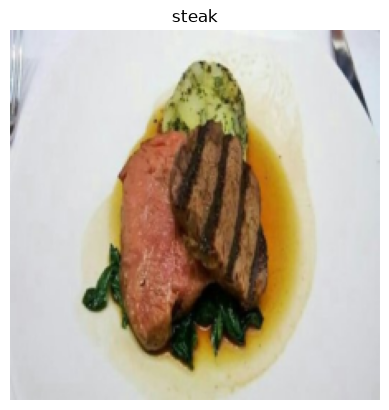

In [28]:
# 1. 查看单张图像
plt.imshow(image.permute(1, 2, 0)) # 调整维度以适配 matplotlib
plt.title(class_names[label])
plt.axis(False);
print(f"Original image shape: {image.shape}")

# 2. 将图像转换为特征图
image_out_of_conv = conv2d(image.unsqueeze(0)) # 添加批次维度，避免形状不匹配
print(f"Image feature map shape: {image_out_of_conv.shape}")

# 3. 展平特征图
image_out_of_conv_flattened = flatten(image_out_of_conv)
print(f"Flattened image feature map shape: {image_out_of_conv_flattened.shape}")

呜呼！ 看起来我们的 `image_out_of_conv_flattened` 形状非常接近我们想要的输出形状：
    
* **Desried 输出（扁平 2D patch ）：** (196, 768) -> ${N \times\left(P^{2} \cdot C\right)}$
* **当前形状：** (1, 768, 196)

唯一的区别是我们当前的形状具有批量大小，并且尺寸与所需输出的顺序不同。

我们怎么能解决这个问题？

那么，我们重新排列尺寸怎么样？

我们可以使用 `torch.Tensor.permute()` 来做到这一点，就像我们在重新排列图像张量以使用 matplotlib 绘制它们时所做的那样。

我们试试看。

In [29]:
# 将展平后的图像 patch embedding 调整为所需形状
image_out_of_conv_flattened_reshaped = image_out_of_conv_flattened.permute(0, 2, 1) # 维度变化：[批次大小, P²×C, patch 数量 N] -> [批次大小, patch 数量 N, embedding 维度 P²×C]
print(f" patch  embedding sequence shape: {image_out_of_conv_flattened_reshaped.shape} -> [batch_size, num_patches, embedding_size]")

 patch  embedding sequence shape: torch.Size([1, 196, 768]) -> [batch_size, num_patches, embedding_size]


是的！！！

我们现在已经使用几个 PyTorch 层为 ViT 架构的 patch  embedding层匹配了所需的输入和输出形状。

我们如何可视化其中一个展平的特征图？

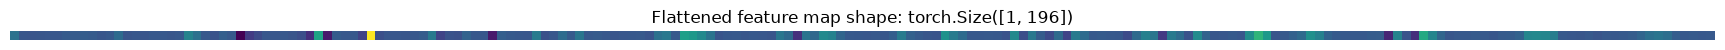

In [30]:
# 获取单张展平特征图
single_flattened_feature_map = image_out_of_conv_flattened_reshaped[:, :, 0] # 索引维度：(batch_size, number_of_patches, embedding_dimension)

# 可视化展平后的特征图
plt.figure(figsize=(22, 22))
plt.imshow(single_flattened_feature_map.detach().numpy())
plt.title(f"Flattened feature map shape: {single_flattened_feature_map.shape}")
plt.axis(False);

嗯，扁平化的特征图在视觉上看起来并不多，但这不是我们关心的，这将是修补embedding层的输出和 ViT 架构其余部分的输入。

> **注意：** [原始 Transformer 架构](https://arxiv.org/abs/1706.03762) 旨在处理文本。 Vision Transformer 架构 (ViT) 的目标是将原始 Transformer 用于图像。 这就是为什么 ViT 架构的输入会按原样处理的原因。 我们实质上是在拍摄 2D 图像并对其进行格式化，使其显示为 1D 文本序列。

我们以张量的形式查看扁平化的特征图怎么样？

In [31]:
# 查看展平特征图的张量形式
single_flattened_feature_map, single_flattened_feature_map.requires_grad, single_flattened_feature_map.shape

(tensor([[ 1.2983e-02, -3.6620e-02, -3.9085e-02, -3.6774e-02, -3.4839e-02,
          -3.5100e-02, -2.7635e-02, -2.7419e-02, -2.4803e-02, -2.7444e-02,
          -3.6623e-02, -3.0652e-02,  1.4024e-04, -3.8495e-02, -3.5732e-02,
          -3.7657e-02, -3.3283e-02, -3.3575e-02, -3.6595e-02, -3.3809e-02,
           4.5783e-02,  1.1545e-02, -3.1313e-02, -4.1865e-02, -1.9777e-02,
          -3.0829e-02, -1.5882e-01, -7.8257e-02, -5.5003e-02, -3.5084e-02,
          -3.5357e-02, -3.2515e-02, -3.7754e-02, -4.9505e-02, -9.9065e-02,
           1.0732e-01, -1.2715e-01, -2.6453e-02, -3.2796e-02, -3.2434e-02,
          -6.9461e-02,  2.9765e-01, -4.6564e-02, -3.5520e-02, -3.5186e-02,
          -3.6785e-02, -3.2322e-02, -2.5760e-02,  2.8382e-02, -6.5689e-02,
          -4.1890e-02, -4.5230e-02, -1.2930e-02, -3.2506e-02, -3.5751e-02,
          -1.2514e-01, -2.1002e-02, -2.9165e-02, -3.3749e-02, -3.4182e-02,
           3.0733e-02, -4.6293e-02, -3.4638e-02,  1.6918e-03, -2.8141e-02,
           2.0244e-02, -3

美丽的！

我们已经将我们的单个 2D 图像转换为 1D 可学习的embedding向量（或 ViT 论文图 1 中的“Flattned Patches 的线性投影”）。

### 4.5 将 ViT patch embedding 层写成一个 Module

是时候将我们为创建 patch  embedding所做的一切放入单个 PyTorch 层了。

我们可以通过继承 `nn.Module` 并创建一个小的 PyTorch“模型”来完成上述所有步骤。

具体来说，我们将：
1. 创建一个名为 `PatchEmbedding` 的类，它是 `nn.Module` 的子类（因此它可以用作 PyTorch 层）。
2. 使用参数 `in_channels=3`、`patch_size=16`（对于 ViT-Base）和 `embedding_dim=768`（这是表 1 中的 ViT-Base 的 $D$）初始化类。
3. 创建一个层，使用 `nn.Conv2d()` 将图像转换为 patch  （就像上面的 4.3 中一样）。
4. 创建一个层以将 patch  特征图展平为一个维度（就像上面的 4.4 中一样）。
5. 定义一个 `forward()` 方法来获取输入并将其传递给在 3 和 4 中创建的层。
6. 确保输出形状反映 ViT 架构所需的输出形状 (${N \times\left(P^{2} \cdot C\right)}$)。

我们开始做吧！

In [32]:
# 1. 创建继承 nn.Module 的类
class PatchEmbedding(nn.Module):
    """将二维图像转换为一维 patch embedding 序列。

    参数：
        in_channels (int): 输入图像的颜色通道数，默认为 3。
        patch_size (int): 将图像切分为 patch 时使用的边长，默认为 16。
        embedding_dim (int): 每个 patch 的 embedding 维度，默认为 768。
    """
    # 2. 使用相应参数初始化类
    def __init__(self,
                 in_channels:int=3,
     patch_size:int=16,
                 embedding_dim:int=768):
        super().__init__()
        self.patch_size = patch_size

        # 3. 创建将图像转换为 patch 的卷积层
        self.patcher = nn.Conv2d(in_channels=in_channels,
                                 out_channels=embedding_dim,
                                 kernel_size=patch_size,
                                 stride=patch_size,
                                 padding=0)

        # 4. 创建将 patch 特征图展平为一维的层
        self.flatten = nn.Flatten(start_dim=2, # 仅将特征图的空间维度展平为一个向量
                                  end_dim=3)

    # 5. 定义 forward 方法
    def forward(self, x):
        # 检查输入形状是否符合要求
        height, width = x.shape[-2:]
        if height % self.patch_size != 0 or width % self.patch_size != 0:
            raise ValueError(
                f"输入图像高宽都必须能被 patch 大小整除，输入：{height}×{width}，"
                f"patch 大小：{self.patch_size}"
            )

        # 执行前向传播
        x_patched = self.patcher(x)
        x_flattened = self.flatten(x_patched)
        # 6. 确保输出维度的顺序正确
        return x_flattened.permute(0, 2, 1) # 将 embedding 调整到最后一维：[batch_size, P^2•C, N] -> [batch_size, N, P^2•C]

`PatchEmbedding` 层已创建！

让我们在单个图像上试一试。

In [33]:
from utils import set_seed
set_seed()

# 创建 patch embedding 层实例
patchify = PatchEmbedding(in_channels=3,
              patch_size=16,
                          embedding_dim=768)

# 输入单张图像
print(f"Input image shape: {image.unsqueeze(0).shape}")
patch_embedded_image = patchify(image.unsqueeze(0)) # 在第 0 维添加批次维度，否则会报错
print(f"Output patch embedding shape: {patch_embedded_image.shape}")

Input image shape: torch.Size([1, 3, 224, 224])
Output patch embedding shape: torch.Size([1, 196, 768])


美丽的！

输出形状与我们希望从 patch  embedding层看到的理想输入和输出形状相匹配：

* **输入：** 图像以 2D 开头，大小为 ${H \times W \times C}$。
* **输出：** 图像被转换为大小为 ${N \times\left(P^{2} \cdot C\right)}$ 的扁平 2D patch 的 1D 序列。

在哪里：
* $(H, W)$ 是原始图像的分辨率。
* $C$ 是通道数。
* $(P, P)$ 是每个图像 patch  的分辨率（** patch  大小**）。
* $N=H W / P^{2}$ 是生成的 patch  数，它也用作 Transformer 的有效输入序列长度。
    
我们现在已经复现了等式 1 的 patch  embedding，但没有复现类token/位置embedding。

我们稍后会谈到这些。

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-replicating-the-patch-embedding-layer.png" width=900 alt="replicating the vision transformer architecture patch embedding layer"/>

*我们的“PatchEmbedding”类（右）复现了图 1 中 ViT 架构的 patch  embedding和 ViT 论文（左）中的公式 1。 但是，尚未创建可学习的类embedding和位置embedding。 这些很快就会到来。*

现在让我们总结一下我们的 `PatchEmbedding` 层。

In [34]:
# 创建示例输入形状
random_input_image = (1, 3, 224, 224)
random_input_image_error = (1, 3, 250, 250) # 图像尺寸与 patch_size 不兼容，因此会报错

    # 查看 PatchEmbedding 的输入输出摘要
summary(PatchEmbedding(),
            input_size=random_input_image, # 可以改为 random_input_image_error，观察不兼容输入引发的错误
            col_names=["input_size", "output_size", "num_params", "trainable"],
            col_width=20,
            row_settings=["var_names"])

Layer (type (var_name))                  Input Shape          Output Shape         Param #              Trainable
PatchEmbedding (PatchEmbedding)          [1, 3, 224, 224]     [1, 196, 768]        --                   True
├─Conv2d (patcher)                       [1, 3, 224, 224]     [1, 768, 14, 14]     590,592              True
├─Flatten (flatten)                      [1, 768, 14, 14]     [1, 768, 196]        --                   --
Total params: 590,592
Trainable params: 590,592
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 115.76
Input size (MB): 0.60
Forward/backward pass size (MB): 1.20
Params size (MB): 2.36
Estimated Total Size (MB): 4.17

### 4.6 创建 class token embedding

好的，我们已经完成了图像 patch  embedding，是时候开始处理类token嵌入（class token embedding.）了。

或来自方程 1 的 $\mathbf{x}_\text {class }$。

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-equation-1-the-class-token.png" width=900 alt="class token embedding highlight from the vision transformer paper figure 1 and section 3.1"/>

*左：来自 ViT 论文的图 1，其中突出显示了我们要重新创建的 "classification token" or `[class]` embedding标记。 右图：与可学习类embeddingtoken相关的 ViT 论文的公式 1 和第 3.1 节。*

从 ViT 论文中阅读第 3.1 节的第二段，我们看到以下描述：

> 与 BERT 的 `[ class ]` 标记类似，我们将可学习的embedding添加到embedding patch  的序列中
$\left(\mathbf{z}_{0}^{0}=\mathbf{x}_{\text {class }}\right)$, Transformer 编码器输出的状态
$\left(\mathbf{z}_{L}^{0}\right)$ 作为图像的表示 $\mathbf{y}$ (Eq. 4). 

> **注：** [BERT](https://arxiv.org/abs/1810.04805) (Bidirectional Encoder Representations from Transformers) 是原始机器学习研究论文之一，使用 Transformer 架构在自然 语言处理 (NLP) 任务，并且是在序列开头具有“[类]”标记的想法的起源，类是序列所属的“分类”类的描述。

所以我们需要“为embedding patch  序列预先准备一个可学习的embedding”。

让我们首先查看我们的embedding式 patch  张量序列（在第 4.5 节中创建）及其形状。

In [35]:
# 查看 patch embedding 及其形状
print(patch_embedded_image)
print(f" patch  embedding shape: {patch_embedded_image.shape} -> [batch_size, number_of_patches, embedding_dimension]")

tensor([[[-0.9115,  0.2843, -0.2503,  ...,  0.7165, -0.3478,  0.2789],
         [-0.9275,  0.2585, -0.2593,  ...,  0.7081, -0.4188,  0.3143],
         [-0.9172,  0.2486, -0.2526,  ...,  0.7081, -0.4283,  0.3325],
         ...,
         [-0.8673,  0.2385, -0.2450,  ...,  0.6627, -0.3954,  0.3070],
         [-0.8566,  0.2273, -0.2378,  ...,  0.6481, -0.3866,  0.3049],
         [-0.8253,  0.2209, -0.2366,  ...,  0.6363, -0.3803,  0.2980]]],
       grad_fn=<PermuteBackward0>)
 patch  embedding shape: torch.Size([1, 196, 768]) -> [batch_size, number_of_patches, embedding_dimension]


为了“将可学习embedding添加到embedding patch  序列中”，我们需要以 `embedding_dimension` ($D$) 的形式创建可学习embedding，然后将其添加到 `number_of_patches` 维度。

在伪代码中：

```python
patch_embedding = [image_patch_1, image_patch_2, image_patch_3...]
class_token = learnable_embedding
patch_embedding_with_class_token = torch.cat((class_token, patch_embedding), dim=1)
```

注意连接（`torch.cat()`）发生在`dim=1`（`number_of_patches`维度）。

让我们为类token创建一个可学习的embedding。

为此，我们将获得批量大小和embedding维度形状，然后我们将创建形状为“[batch_size, 1, embedding_dimension]”的“torch.ones()”张量。

我们将通过使用 `requires_grad=True` 将其传递给 `nn.Parameter()` 来使张量可学习。

In [36]:
# 获取批次大小和 embedding 维度
batch_size = patch_embedded_image.shape[0]
embedding_dimension = patch_embedded_image.shape[-1]

# 创建可学习的 class token embedding，其维度与 embedding 维度 D 相同
class_token = nn.Parameter(torch.ones(batch_size, 1, embedding_dimension), # 维度：[批次大小, token 数量, embedding 维度]
                           requires_grad=True) # 确保 embedding 可以学习

# 显示 class_token 的前 10 个值
print(class_token[:, :, :10])

# 打印 class_token 的形状
print(f"Class token shape: {class_token.shape} -> [batch_size, number_of_tokens, embedding_dimension]")

tensor([[[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]]], grad_fn=<SliceBackward0>)
Class token shape: torch.Size([1, 1, 768]) -> [batch_size, number_of_tokens, embedding_dimension]


> **注意：** 这里我们只是将类tokenembedding创建为 [`torch.ones()`](https://pytorch.org/docs/stable/generated/torch.ones.html) 用于演示 目的，实际上，你可能会使用 [`torch.randn()`](https://pytorch.org/docs/stable/generated/torch.randn.html) 创建类token嵌入（因为机器学习是 关于利用受控随机性的力量，你通常从一个随机数开始，并随着时间的推移对其进行改进）。

看看 `class_token` 的 `number_of_tokens` 维度如何为 `1`，因为我们只想在 patch  embedding序列的开头添加一个类token值。

现在我们已经有了类标记embedding，让我们将它添加到我们的图像 patch  序列`patch_embedded_image`中。

我们可以使用 [`torch.cat()`](https://pytorch.org/docs/stable/generated/torch.cat.html) 并设置 `dim=1`（所以 `class_token`'s ` number_of_tokens 维度预置在 `patch_embedded_image` 的 `number_of_patches` 维度中）。

In [37]:
# 将 class token embedding 添加到 patch embedding 序列前面
patch_embedded_image_with_class_embedding = torch.cat((class_token, patch_embedded_image),
                                                      dim=1) # 沿第 1 维拼接

# 打印添加 class token embedding 后的 patch embedding 序列
print(patch_embedded_image_with_class_embedding)
print(f"Sequence of patch embeddings with class token prepended shape: {patch_embedded_image_with_class_embedding.shape} -> [batch_size, number_of_patches, embedding_dimension]")

tensor([[[ 1.0000,  1.0000,  1.0000,  ...,  1.0000,  1.0000,  1.0000],
         [-0.9115,  0.2843, -0.2503,  ...,  0.7165, -0.3478,  0.2789],
         [-0.9275,  0.2585, -0.2593,  ...,  0.7081, -0.4188,  0.3143],
         ...,
         [-0.8673,  0.2385, -0.2450,  ...,  0.6627, -0.3954,  0.3070],
         [-0.8566,  0.2273, -0.2378,  ...,  0.6481, -0.3866,  0.3049],
         [-0.8253,  0.2209, -0.2366,  ...,  0.6363, -0.3803,  0.2980]]],
       grad_fn=<CatBackward0>)
Sequence of patch embeddings with class token prepended shape: torch.Size([1, 197, 768]) -> [batch_size, number_of_patches, embedding_dimension]


好的！ 可学习的类token前置！

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-equation-1-prepending-the-learnable-class-token.png" width=900 alt="going from a sequence of patch embeddings, creating a learnable class token and then prepending it to the patch embeddings"/>

*回顾我们为创建可学习类标记所做的工作，我们从由`PatchEmbedding()` 在单个图像上创建的一系列图像 patch  embedding开始，然后我们创建了一个可学习类标记，每个embedding维度都有一个值 然后将其添加到原始的 patch  embedding序列中。 **注意：** 使用 `torch.ones()` 创建可学习的类token主要仅用于演示目的，实际上，你希望使用 `torch.randn()` 创建它。*

### 4.7 创建 the position embedding 

好吧，我们已经有了类tokenembedding和 patch  embedding，现在我们如何创建位置embedding呢？

Or $\mathbf{E}_{\text {pos }}$ from equation 1 where $E$ stands for "embedding".

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-equation-1-the-position-embeddings.png" width=900 alt="extracting the position embeddings from the vision transformer architecture and comparing them to other sections of the vision transformer paper"/>

*左：来自 ViT 论文的图 1，其中突出显示了我们要重新创建的位置embedding。 右图：与位置embedding相关的 ViT 论文的公式 1 和第 3.1 节。*

让我们通过阅读 ViT 论文的第 3.1 节了解更多信息（我的粗体字）：

> 位置embedding被添加到 patch  embedding中以保留位置信息。 我们使用**标准可学习的 1D 位置embedding**，因为我们没有观察到使用更高级的 2D 感知位置嵌入（附录 D.4）带来的显着性能提升。 生成的embedding向量序列用作编码器的输入。

通过“保留位置信息”，作者的意思是他们希望架构知道 patch  的“顺序”。例如， patch  二在 patch  一之后， patch  三在 patch  二之后，以此类推。

在考虑图像中的内容时，此位置信息可能很重要（没有位置信息，扁平序列可能被视为没有顺序，因此没有 patch  与任何其他 patch  相关）。

要开始创建位置embedding，让我们查看当前的embedding。

In [38]:
# 查看添加 class embedding 后的 patch embedding 序列
patch_embedded_image_with_class_embedding, patch_embedded_image_with_class_embedding.shape

(tensor([[[ 1.0000,  1.0000,  1.0000,  ...,  1.0000,  1.0000,  1.0000],
          [-0.9115,  0.2843, -0.2503,  ...,  0.7165, -0.3478,  0.2789],
          [-0.9275,  0.2585, -0.2593,  ...,  0.7081, -0.4188,  0.3143],
          ...,
          [-0.8673,  0.2385, -0.2450,  ...,  0.6627, -0.3954,  0.3070],
          [-0.8566,  0.2273, -0.2378,  ...,  0.6481, -0.3866,  0.3049],
          [-0.8253,  0.2209, -0.2366,  ...,  0.6363, -0.3803,  0.2980]]],
        grad_fn=<CatBackward0>),
 torch.Size([1, 197, 768]))

等式 1 表明位置嵌入 ($\mathbf{E}_{\text {pos }}$) 应该具有 $(N + 1) \times D$ 的形状：

$$\mathbf{E}_{\text {pos }} \in \mathbb{R}^{(N+1) \times D}$$

其中：
* $N=H W / P^{2}$ 是生成的 patch  数，它也用作 Transformer 的有效输入序列长度（ patch  数）。
* $D$ 是** patch  embeddings** 的大小，$D$ 的不同值可以在表 1（embedding维度）中找到。

幸运的是，我们已经拥有了这两个值。

所以让我们用 `torch.ones()` 创建一个可学习的 1D embedding来创建 $\mathbf{E}_{\text {pos }}$。

In [39]:
# 计算 N（patch 数量）
number_of_patches = int((height * width) / patch_size**2)

# 获取 embedding 维度
embedding_dimension = patch_embedded_image_with_class_embedding.shape[2]

# 创建可学习的一维位置 embedding
position_embedding = nn.Parameter(torch.ones(1,
                                             number_of_patches+1,
                                             embedding_dimension),
                                  requires_grad=True) # 确保参数可以学习

# 查看前 10 个位置的前 10 个 embedding 值，并检查位置 embedding 的形状
print(position_embedding[:, :10, :10])
print(f"Position embedding shape: {position_embedding.shape} -> [batch_size, number_of_patches, embedding_dimension]")

tensor([[[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]]], grad_fn=<SliceBackward0>)
Position embedding shape: torch.Size([1, 197, 768]) -> [batch_size, number_of_patches, embedding_dimension]


> **注意：** 仅将位置embedding创建为 `torch.ones()` 用于演示目的，实际上，你可能会使用 `torch.randn()` 创建位置嵌入（以随机数开头，然后 通过梯度下降改进）。

位置embedding已创建！

让我们将它们添加到带有前置类标记的 patch  embedding序列中。

In [40]:
# 将位置 embedding 加到 patch 和 class token embedding 上
patch_and_position_embedding = patch_embedded_image_with_class_embedding + position_embedding
print(patch_and_position_embedding)
print(f" patch  embeddings, class token prepended and positional embeddings added shape: {patch_and_position_embedding.shape} -> [batch_size, number_of_patches, embedding_dimension]")

tensor([[[2.0000, 2.0000, 2.0000,  ..., 2.0000, 2.0000, 2.0000],
         [0.0885, 1.2843, 0.7497,  ..., 1.7165, 0.6522, 1.2789],
         [0.0725, 1.2585, 0.7407,  ..., 1.7081, 0.5812, 1.3143],
         ...,
         [0.1327, 1.2385, 0.7550,  ..., 1.6627, 0.6046, 1.3070],
         [0.1434, 1.2273, 0.7622,  ..., 1.6481, 0.6134, 1.3049],
         [0.1747, 1.2209, 0.7634,  ..., 1.6363, 0.6197, 1.2980]]],
       grad_fn=<AddBackward0>)
 patch  embeddings, class token prepended and positional embeddings added shape: torch.Size([1, 197, 768]) -> [batch_size, number_of_patches, embedding_dimension]


注意embedding张量中每个元素的值如何增加 1（这是因为位置embedding是使用 `torch.ones()` 创建的）。

> **注意：** 如果我们愿意，我们可以将类tokenembedding和位置embedding都放入它们自己的层中。 但是我们稍后会在第 8 节中看到如何将它们合并到整个 ViT 架构的 `forward()` 方法中。

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-equation-1-patch-embeddings-with-learnable-class-token-and-position-embeddings.png" width=900 alt=" patch  embeddings with learnable class token and position embeddings"/>

*我们用于将位置embedding添加到 patch  embedding和类token序列的工作流程。 **注意：** `torch.ones()` 仅用于创建embedding以用于说明目的，在实践中，你可能会使用 `torch.randn()` 以随机数开头。*

### 4.8 将它们放在一起 : 从图像到 embedding

好的，我们在将输入图像转换为embedding和复现 ViT 论文第 3.1 节中的方程 1 方面取得了一定的进展：

$$
\begin{aligned}
\mathbf{z}_{0} &=\left[\mathbf{x}_{\text {class }} ; \mathbf{x}_{p}^{1} \mathbf{E} ; \mathbf{x}_{p}^{2} \mathbf{E} ; \cdots ; \mathbf{x}_{p}^{N} \mathbf{E}\right]+\mathbf{E}_{\text {pos }}, & & \mathbf{E} \in \mathbb{R}^{\left(P^{2} \cdot C\right) \times D}, \mathbf{E}_{\text {pos }} \in \mathbb{R}^{(N+1) \times D}
\end{aligned}
$$

现在让我们将所有内容放在一个代码单元中，然后从输入图像 ($\mathbf{x}$) 到输出嵌入 ($\mathbf{z}_0$)。

我们可以这样做：
1. 设置 patch  大小（我们将使用 `16`，因为它在整个论文和 ViT-Base 中被广泛使用）。
2. 获取单个图像，打印其形状并存储其高度和宽度。
3. 为单个图像添加批量维度，使其与我们的 `PatchEmbedding` 层兼容。
4. 使用 `patch_size=16` 和 `embedding_dim=768` （来自 ViT-Base 的表 1）创建一个 `PatchEmbedding` 层（我们在第 4.5 节中制作的那个）。
5. 将单个图像通过 4 中的 `PatchEmbedding` 层以创建一个 patch  embedding序列。
6. 创建一个类tokenembedding，如第 4.6 节。
7. 在步骤 5 中创建的 patch  embedding之前添加类tokenembedding。
8. 像第 4.7 节一样创建位置embedding。
9. 将位置embedding添加到在步骤 7 中创建的类标记和 patch  embedding。

我们还将确保使用 `set_seeds()` 设置随机种子，并在此过程中打印出不同张量的形状。

In [41]:
set_seed()

# 1. 设置 patch 大小
patch_size = 16

# 2. 打印原始图像张量形状，并获取图像的高度和宽度
print(f"Image tensor shape: {image.shape}")
height, width = image.shape[1], image.shape[2]

# 3. 获取图像张量并添加批次维度
x = image.unsqueeze(0)
print(f"Input image with batch dimension shape: {x.shape}")

# 4. 创建 patch embedding 层
patch_embedding_layer = PatchEmbedding(in_channels=3,
                           patch_size=patch_size,
                                       embedding_dim=768)

# 5. 将图像输入 patch embedding 层
patch_embedding = patch_embedding_layer(x)
print(f"Patching embedding shape: {patch_embedding.shape}")

# 6. 创建 class token embedding
batch_size = patch_embedding.shape[0]
embedding_dimension = patch_embedding.shape[-1]
class_token = nn.Parameter(torch.ones(batch_size, 1, embedding_dimension),
                           requires_grad=True) # 确保参数可以学习
print(f"Class token embedding shape: {class_token.shape}")

# 7. 将 class token embedding 拼接到 patch embedding 前面
patch_embedding_class_token = torch.cat((class_token, patch_embedding), dim=1)
print(f" patch  embedding with class token shape: {patch_embedding_class_token.shape}")

# 8. 创建位置 embedding
number_of_patches = int((height * width) / patch_size**2)
position_embedding = nn.Parameter(torch.ones(1, number_of_patches+1, embedding_dimension),
                                  requires_grad=True) # 确保参数可以学习

# 9. 将位置 embedding 加到包含 class token 的 patch embedding 上
patch_and_position_embedding = patch_embedding_class_token + position_embedding
print(f" patch  and position embedding shape: {patch_and_position_embedding.shape}")

Image tensor shape: torch.Size([3, 224, 224])
Input image with batch dimension shape: torch.Size([1, 3, 224, 224])
Patching embedding shape: torch.Size([1, 196, 768])
Class token embedding shape: torch.Size([1, 1, 768])
 patch  embedding with class token shape: torch.Size([1, 197, 768])
 patch  and position embedding shape: torch.Size([1, 197, 768])


从单个图像到在单个代码单元中修补和定位embedding。

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-equation-1-putting-it-all-together.png" width=900 alt="mapping equation 1 from the vision transformer paper to pytorch code"/> 

*将 ViT 论文中的方程式 1 映射到我们的 PyTorch 代码。 这是论文复现的精髓，将研究论文转化为可用代码。*

现在我们有了一种方法来编码我们的图像并将它们传递给 ViT 论文图 1 中的 Transformer Encoder。

<img src="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/images/08-vit-paper-architecture-animation-full-architecture.gif" alt="Vision transformer architecture animation, going from a single image and passing it through a patch embedidng layer and then passing it through the transformer encoder." width=900/>

*动画整个 ViT 工作流程：从 patch  embedding到转换器编码器再到 MLP 头。*

从代码的角度来看，创建 patch  embedding可能是复现 ViT 论文的最大部分。

ViT 论文的许多其他部分，例如 Multi-Head Attention 和 Norm 层，可以使用现有的 PyTorch 层创建。

向前！

## 5. 公式二 : 多头自注意力 Multi-Head Attention (MSA)

我们已经修补并embedding了输入数据，现在让我们进入 ViT 架构的下一部分。

首先，我们将 Transformer Encoder 部分分为两部分（从小处开始，必要时增加）。

第一个是等式2，第二个是等式3。

回忆方程 2 状态：

$$
\begin{aligned}
\mathbf{z}_{\ell}^{\prime} &=\operatorname{MSA}\left(\operatorname{LN}\left(\mathbf{z}_{\ell-1}\right)\right)+\mathbf{z}_{\ell-1}, & & \ell=1 \ldots L
\end{aligned}
$$

这表示多头注意力 (MSA) 层包裹在具有残差连接的 LayerNorm (LN) 层中（层的输入被添加到层的输出中）。

我们将等式 2 称为“MSA 块”。

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-equation-2-msa-block-mapped-to-equation.png" alt="mapping equation 2 from the ViT paper to the ViT architecture diagram in figure 1" width=900/> 

***左：** ViT 论文中的图 1 具有 Multi-Head Attention 和 Norm 层以及 Transformer Encoder 块中突出显示的残差连接 (+)。 **右：** 将 Multi-Head Self Attention (MSA) 层、Norm 层和残差连接映射到 ViT 论文中等式 2 的相应部分。*

你在研究论文中发现的许多层已经在现代深度学习框架（例如 PyTorch）中实现。

话虽如此，要使用 PyTorch 代码复现这些层和剩余连接，我们可以使用：
* **多头自注意 (MSA)** - [`torch.nn.MultiheadAttention()`](https://pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html)。
* **Norm（LN 或 LayerNorm）** - [`torch.nn.LayerNorm()`](https://pytorch.org/docs/stable/generated/torch.nn.LayerNorm.html)。
* **Residual connection** - 将输入添加到输出（稍后我们将在第 7.1 节中创建完整的 Transformer Encoder 块时看到这一点）。

[Layer Normalization](https://paperswithcode.com/method/layer-normalization)（`torch.nn.LayerNorm()` 或 Norm 或 LayerNorm 或 LN）在最后一个维度上对输入进行标准化。

你可以在 [PyTorch 文档](https://pytorch.org/docs/stable/generated/torch.nn.LayerNorm.html) 中找到 `torch.nn.LayerNorm()` 的正式定义。

PyTorch 的 `torch.nn.LayerNorm()` 的主要参数是 `normalized_shape`，我们可以将其设置为等于我们想要规范化的维度大小（在我们的例子中，它将是 $D$ 或 `768 ` 用于 ViT 基）。

它有什么作用？

层归一化有助于改善训练时间和模型泛化（适应看不见的数据的能力）。

我喜欢将任何类型的规范化视为“将数据转换为类似的格式”或“将数据样本转换为类似的分布”。

想象一下试图走上（或下）一组不同高度和长度的楼梯。

每一步都要进行一些调整，对吧？

而且你在每一步学到的东西对下一步都没有必要的帮助，因为它们都不同，增加了你走楼梯的时间。

规范化（包括层规范化）相当于使所有楼梯的高度和长度相同，除了楼梯是你的数据样本。

所以就像你可以走上（或下）具有相似高度和长度的楼梯比那些高度和宽度不相等的楼梯要容易得多，神经网络可以优化具有相似分布（相似的平均值和标准偏差）的数据样本比那些具有不同的分布。

### 5.2 Multi-Head Self Attention (MSA) layer 

self-attention 和 multi-head attention (self-attention 多次应用) 的威力以 [*Attention is all you need*](https://arxiv.org/abs/1706.03762) 中介绍的原始 Transformer 架构的形式展示) 研究论文。

最初是为文本输入而设计的，最初的自注意力机制采用一系列单词，然后计算哪个单词应该对另一个单词更加“注意”。

换句话说，在“the dog jumped over the fence”这句话中，“dog”这个词可能与“jumped”和“fence”密切相关。

这是简化的，但前提仍然是图像。

由于我们的输入是一系列图像块而不是单词，因此自注意力和多头注意力将计算图像的哪个块与另一个块最相关，最终形成图像的学习表示。

但最重要的是，该层根据数据自行执行此操作（我们不告诉它要学习什么模式）。

如果使用 MSA 形成的层学习表示是好的，我们将在模型的性能中看到结果。

网上有很多资源可以在线了解更多关于 Transformer 架构和注意力机制的信息，例如 Jay Alammar 的精彩 [Illustrated Transformer 帖子](https://jalammar.github.io/illustrated-transformer/) 和 [Illustrated Attention post](https ://jalammar.github.io/visualizing-neural-machine-translation-mechanics-of-seq2seq-models-with-attention/）。

我们将更多地专注于编码现有的 PyTorch MSA 实现，而不是创建我们自己的实现。

但是，你可以在附录 A 中找到 ViT 论文的 MSA 实现的正式定义：

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-equation-2-appendix-A.png" alt="vision transformer paper figure 1 highlighted with equation 2 and appendix A" width=900/>

***左：** ViT 论文图 1 中的 Vision Transformer 架构概述。 **右：** ViT 论文第 3.1 节和附录 A 的公式 2 的定义在图 1 中突出显示以反映它们各自的部分。*

上图突出显示了 MSA 层的三重embedding输入。

这被称为 **query、key、value** 输入或简称 **qkv**，这是自注意力机制的基础。

在我们的例子中，三重embedding输入将是 Norm 层输出的三个版本，一个用于查询、键和值。

或者我们在 4.8 节中创建的层归一化图像 patch  和位置embedding的三个版本。

我们可以使用带有参数的`torch.nn.MultiheadAttention()`在PyTorch中实现MSA层：
* `embed_dim` - 表 1 中的embedding维度（隐藏大小 $D$）。
* `num_heads` - 使用多少注意力头（这是术语“多头”的来源），该值也在表 1（头）中。
* `dropout` - 是否对注意力层应用 dropout（根据附录 B.1，在 qkv-projections 之后不使用 dropout）。
* `batch_first` - 我们的批次维度排在第一位吗？ （是的，它确实）

### 5.3 使用 PyTorch layers 复现公式 2 

让我们将我们讨论过的关于等式 2 中的 LayerNorm (LN) 和 Multi-Head Attention (MSA) 层的所有内容付诸实践。

为此，我们将：

1. 创建一个名为 `MultiheadSelfAttentionBlock` 的类，它继承自 `torch.nn.Module`。
2. 使用 ViT-Base 模型的 ViT 论文表 1 中的超参数初始化类。
3. 使用 `torch.nn.LayerNorm()` 创建一个层归一化（LN）层，其 `normalized_shape` 参数与我们的embedding维度（表 1 中的 $D$）相同。
4. 使用适当的 `embed_dim`、`num_heads`、`dropout` 和 `batch_first` 参数创建一个多头注意力 (MSA) 层。
5. 为我们的类创建一个 `forward()` 方法，通过 LN 层和 MSA 层传递输入。

In [42]:
# 1. 创建继承 nn.Module 的类
class MultiheadSelfAttentionBlock(nn.Module):
    """创建多头自注意力模块，简称 MSA 模块。"""
    # 2. 使用表 1 中的超参数初始化类
    def __init__(self,
                 embedding_dim:int=768, # 来自表 1 的 ViT-Base 隐藏维度 D
                 num_heads:int=12, # 来自表 1 的 ViT-Base 注意力头数
                 attn_dropout:float=0): # 论文中的 MSA 模块似乎没有使用 dropout
        super().__init__()

        # 3. 创建层归一化层（LN）
        self.layer_norm = nn.LayerNorm(normalized_shape=embedding_dim)

        # 4. 创建多头注意力层（MSA）
        self.multihead_attn = nn.MultiheadAttention(embed_dim=embedding_dim,
                                                    num_heads=num_heads,
                                                    dropout=attn_dropout,
                                                    batch_first=True) # 将批次维度放在第 0 维

    # 5. 创建 forward() 方法，让数据依次通过各层
    def forward(self, x):
        x = self.layer_norm(x)
        attn_output, _ = self.multihead_attn(query=x, # 查询向量的 embedding
                                             key=x, # 键向量的 embedding
                                             value=x, # 值向量的 embedding
                                             need_weights=False) # 仅返回层输出，不返回注意力权重
        return attn_output

> **注意：** 与图 1 不同，我们的 `MultiheadSelfAttentionBlock` 不包括跳过或剩余连接（等式 2 中的“$+\mathbf{z}_{\ell-1}$”），我们将 当我们稍后在第 7.1 节中创建整个 Transformer Encoder 时包括这个。

MSABlock 创建！

让我们通过创建 `MultiheadSelfAttentionBlock` 的实例并传递我们在 4.8 节中创建的 `patch_and_position_embedding` 变量来尝试一下。

In [43]:
# 创建多头自注意力模块实例
multihead_self_attention_block = MultiheadSelfAttentionBlock(embedding_dim=768, # 来自表 1
                                                             num_heads=12) # 来自表 1

# 将图像的 patch 和位置 embedding 输入多头自注意力模块
patched_image_through_msa_block = multihead_self_attention_block(patch_and_position_embedding)
print(f"Input shape of MSA block: {patch_and_position_embedding.shape}")
print(f"Output shape MSA block: {patched_image_through_msa_block.shape}")

Input shape of MSA block: torch.Size([1, 197, 768])
Output shape MSA block: torch.Size([1, 197, 768])


请注意，当数据通过 MSA 块时，数据的输入和输出形状如何保持不变。

这并不意味着数据在经过时不会发生变化。

你可以尝试打印输入和输出张量以查看它是如何变化的（尽管这种变化将跨越 `1 * 197 * 768` 值并且可能难以可视化）。

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-equation-2-in-code.png" width=900 alt="vision transformer paper with equation 2 of figure 1 highlighted and equation 2 turned into code"/>

***左：** 图 1 中的 Vision Transformer 架构，突出显示了 Multi-Head Attention 和 LayerNorm 层，这些层构成了论文第 3.1 节中的方程式 2。 **右：** 使用 PyTorch 层复现等式 2（最后没有跳过连接）。*

我们现在正式复现了方程 2（除了最后的残差连接，但我们将在第 7.1 节中讨论）！

到下一个！

## 6. 公式 3 : 多层感知机 Multilayer Perceptron (MLP)

我们在这里很顺利！

让我们继续并复现方程 3：

$$
\begin{aligned}
\mathbf{z}_{\ell} &=\operatorname{MLP}\left(\operatorname{LN}\left(\mathbf{z}_{\ell}^{\prime}\right)\right)+\mathbf{z}_{\ell}^{\prime}, & & \ell=1 \ldots L
\end{aligned}
$$ 

这里 MLP 代表“多层感知器”，LN 代表“层归一化”（如上所述）。

最后添加的是跳过/剩余连接。

我们将等式 3 称为 Transformer 编码器的“MLP 块”（注意我们如何继续将架构分解成更小的块的趋势）。

<img src="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/images/08-vit-paper-equation-3-annotated.png" alt="mapping equation 3 from the ViT paper to the ViT architecture diagram in figure 1" width=900/> 

***左：** ViT 论文中的图 1，其中 MLP 和 Norm 层以及在 Transformer Encoder 块中突出显示的残差连接 (+)。 **右：** 将多层感知器 (MLP) 层、Norm 层 (LN) 和残差连接映射到 ViT 论文中等式 3 的相应部分。*

### 6.1 MLP layer(s)

术语 [MLP](https://en.wikipedia.org/wiki/Multilayer_perceptron) 非常广泛，因为它几乎可以指代 *multiple* 层的几乎任何组合（因此多层感知器中的“multi”）。

但它通常遵循以下模式：

`线性层->非线性层->线性层->非线性层`

在 ViT 论文的情况下，MLP 结构在第 3.1 节中定义：

> MLP 包含两个具有 GELU 非线性的层。

其中“两层”是指线性层（[`torch.nn.Linear()`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html) 在 PyTorch 中）和“GELU 非线性”是 GELU（高斯误差线性单位）非线性激活函数（[`torch.nn.GELU()`](https://pytorch.org/docs/stable/generated/torch.nn.GELU.html)在 PyTorch 中）。

> **注意：** 线性层（`torch.nn.Linear()`）有时也可以称为“密集层”("dense layer")或“前馈层”("feedforward layer".)。 一些论文甚至使用所有三个术语来描述同一事物（如 ViT 论文中所示）。

关于 MLP 块的另一个偷偷摸摸的细节直到附录 B.1（培训）才出现：

> 表 3 总结了我们针对不同模型的训练设置。 ... Dropout，当使用时，**在除 qkv-projections 之外的每个密集层之后应用，并且直接在添加 positional- 到 patch  embedding之后。**

这意味着 MLP 块中的每个线性层（或密集层）都有一个 dropout 层[`torch.nn.Dropout()`](https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html)在 PyTorch 中）。

其值可以在 ViT 论文的表 3 中找到（对于 ViT-Base，`dropout=0.1`）。

知道了这一点，我们的 MLP 块的结构将是：


`layer norm -> linear layer -> non-linear layer -> dropout -> linear layer -> dropout`

使用表 1 中可用的线性层的超参数值（MLP 大小是线性层之间的隐藏单元的数量，隐藏大小 $D$ 是 MLP 块的输出大小）。

### 6.2 使用 PyTorch layers 复现公式 3

让我们将我们讨论过的关于等式 3 中的 LayerNorm (LN) 和 MLP (MSA) 层的所有内容付诸实践。

为此，我们将：

1. 创建一个名为 `MLPBlock` 的类，它继承自 `torch.nn.Module`。
2. 使用 ViT-Base 模型的 ViT 论文的表 1 和表 3 中的超参数初始化类。
3. 使用 `torch.nn.LayerNorm()` 创建一个层归一化（LN）层，其 `normalized_shape` 参数与我们的embedding维度（表 1 中的 $D$）相同。
4. 使用 `torch.nn.Linear()`、`torch.nn.Dropout()` 和 `torch.nn.GELU()` 使用表 1 中的适当超参数值和 表3。
5. 为我们的类创建一个 `forward()` 方法，通过 LN 层和 MLP 层传递输入。

In [44]:
# 1. 创建继承 nn.Module 的类
class MLPBlock(nn.Module):
    """创建包含层归一化的多层感知机模块，简称 MLP 模块。"""
    # 2. 使用表 1 和表 3 中的超参数初始化类
    def __init__(self,
                 embedding_dim:int=768, # 来自表 1 的 ViT-Base 隐藏维度 D
                 mlp_size:int=3072, # 来自表 1 的 ViT-Base MLP 隐藏层维度
                 dropout:float=0.1): # 来自表 3 的 ViT-Base dropout 概率
        super().__init__()

        # 3. 创建层归一化层（LN）
        self.layer_norm = nn.LayerNorm(normalized_shape=embedding_dim)

        # 4. 创建多层感知机（MLP）
        self.mlp = nn.Sequential(
            nn.Linear(in_features=embedding_dim,
                      out_features=mlp_size),
            nn.GELU(), # 论文第 3.1 节：MLP 包含两个全连接层，中间使用 GELU 非线性激活
            nn.Dropout(p=dropout),
            nn.Linear(in_features=mlp_size, # in_features 需要与上一层的 out_features 一致
                      out_features=embedding_dim), # 将输出维度还原为 embedding_dim
            nn.Dropout(p=dropout) # 使用 dropout 时，在每个全连接层之后应用
        )

    # 5. 创建 forward() 方法，让数据依次通过各层
    def forward(self, x):
        x = self.layer_norm(x)
        x = self.mlp(x)
        return x

> **注意：** 与图 1 不同，我们的 `MLPBlock()` 不包括跳过或残差连接（等式 3 中的“$+\mathbf{z}_{\ell}^{\prime}$” )，我们将在稍后创建整个 Transformer 编码器时包含它。

MLPBlock 类创建！

让我们通过创建 `MLPBlock` 的实例并传递我们在 5.3 节中创建的 `patched_image_through_msa_block` 变量来尝试一下。

In [45]:
# 创建 MLPBlock 实例
mlp_block = MLPBlock(embedding_dim=768, # 来自表 1
                     mlp_size=3072, # 来自表 1
                     dropout=0.1) # 来自表 3

# 将多头自注意力模块的输出输入 MLPBlock
patched_image_through_mlp_block = mlp_block(patched_image_through_msa_block)
print(f"Input shape of MLP block: {patched_image_through_msa_block.shape}")
print(f"Output shape MLP block: {patched_image_through_mlp_block.shape}")

Input shape of MLP block: torch.Size([1, 197, 768])
Output shape MLP block: torch.Size([1, 197, 768])


请注意，当数据进出 MLP 块时，数据的输入和输出形状如何再次保持不变。

然而，当数据通过 MLP 块中的 nn.Linear() 层时，形状确实发生了变化（从表 1 扩展为 MLP 大小，然后从表 1 压缩回隐藏大小 $D$）。

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/08-vit-paper-equation-3-mapped-to-code.png" width=900 alt="vision transformer paper with equation 3 of figure 1 highlighted and equation 3 turned into code"/>

*左：图 1 中的 Vision Transformer 架构，突出显示了 MLP 和 Norm 层，这些层构成了论文第 3.1 节中的方程 3。 右图：使用 PyTorch 层复现方程 3（最后没有跳过连接）。*

嗬嗬！

公式 3 复现了（除了最后的剩余连接，但我们将在第 7.1 节中讨论）！

现在我们在 PyTorch 代码中得到了方程 2 和 3，现在让我们将它们放在一起创建 Transformer Encoder。

## 7. 创建 Transformer Encoder 

是时候将我们的“MultiheadSelfAttentionBlock”（等式 2）和“MLPBlock”（等式 3）堆叠在一起并创建 ViT 架构的 Transformer 编码器了。

在深度学习中，[“编码器 encoder”或“自动编码器”](https://paperswithcode.com/method/autoencoder)通常是指“编码”输入（将其转换为某种形式的数字表示）的一堆层 ）。

在我们的例子中，Transformer Encoder 将使用一系列交替的 MSA 块和 MLP 块层将我们的修补图像embedding编码为学习表示，根据 ViT 论文的第 3.1 节：

> Transformer 编码器（Vaswani 等人，2017）由多头自注意力（MSA，见附录 A）和 MLP 块（方程 2、3）的交替层组成。 **Layernorm (LN) 在每个区块之前应用**，**在每个区块之后应用剩余连接**（Wang et al., 2019; Baevski & Auli, 2019）。

我们已经创建了 MSA 和 MLP 块，但是残差连接(Residual connections)呢？

[Residual connections](https://paperswithcode.com/method/residual-connection) (也称跳跃连接skip connections), 首先出现在 [*Deep Residual Learning for Image Recognition*](https://arxiv.org/abs/1512.03385v1) 通过将层输入添加到其后续输出来实现.

子序列输出可能是稍后的一层或多层。

在 ViT 架构的情况下，残差连接意味着 MSA 块的输入在传递到 MLP 块之前被添加回 MSA 块的输出。

在 MLP 块进入下一个 Transformer Encoder 块之前，也会发生同样的事情。

或者在伪代码中：

`x_input -> MSA_block -> [MSA_block_output + x_input] -> MLP_block -> [MLP_block_output + MSA_block_output + x_input] -> ...`

这是做什么的？

残差连接背后的主要思想之一是它们防止权重值和梯度更新变得太小，从而允许更深的网络，进而允许学习更深的表示。

> **注：** 标志性的计算机视觉架构“ResNet”之所以如此命名，是因为引入了*residual* 连接。 你可以在 [`torchvision.models`](https://pytorch.org/vision/stable/models.html) 中找到许多预训练版本的 ResNet 架构。

### 7.1 通过组合我们创建的层来创建 Transformer Encoder

说得够多了，让我们看看实际情况，并通过组合我们之前创建的层来使用 PyTorch 制作一个 ViT Transformer 编码器。

为此，我们将：

1. 创建一个名为 `TransformerEncoderBlock` 的类，它继承自 `torch.nn.Module`。
2. 使用 ViT-Base 模型的 ViT 论文的表 1 和表 3 中的超参数初始化类。
3. 使用 5.2 节中的“MultiheadSelfAttentionBlock”和适当的参数为方程 2 实例化一个 MSA 块。
4. 使用 6.2 节中的“MLPBlock”和适当的参数，为方程 3 实例化一个 MLP 块。
5. 为我们的“TransformerEncoderBlock”类创建一个“forward()”方法。
6. 为 MSA 块创建一个残差连接（对于等式 2）。
7. 为 MLP 块创建一个残差连接（对于等式 3）。

In [46]:
# 1. 创建继承 nn.Module 的类
class TransformerEncoderBlock(nn.Module):
    """创建 Transformer 编码器模块。"""
    # 2. 使用表 1 和表 3 中的超参数初始化类
    def __init__(self,
                 embedding_dim:int=768, # 来自表 1 的 ViT-Base 隐藏维度 D
                 num_heads:int=12, # 来自表 1 的 ViT-Base 注意力头数
                 mlp_size:int=3072, # 来自表 1 的 ViT-Base MLP 隐藏层维度
                 mlp_dropout:float=0.1, # 来自表 3 的 ViT-Base 全连接层 dropout 概率
                 attn_dropout:float=0): # 注意力层的 dropout 概率
        super().__init__()

        # 3. 创建 MSA 模块（公式 2）
        self.msa_block = MultiheadSelfAttentionBlock(embedding_dim=embedding_dim,
                                                     num_heads=num_heads,
                                                     attn_dropout=attn_dropout)

        # 4. 创建 MLP 模块（公式 3）
        self.mlp_block =  MLPBlock(embedding_dim=embedding_dim,
                                   mlp_size=mlp_size,
                                   dropout=mlp_dropout)

    # 5. 创建 forward() 方法
    def forward(self, x):

        # 6. 为 MSA 模块添加残差连接（输入与输出相加）
        x =  self.msa_block(x) + x

        # 7. 为 MLP 模块添加残差连接（输入与输出相加）
        x = self.mlp_block(x) + x

        return x


<img src="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/images/08-vit-paper-transformer-encoder-highlighted.png" width=900 alt="vision transformer architecture with transformer encoder blocks highlighted"/>

***左：** ViT 论文中的图 1 突出显示了 ViT 架构的 Transformer Encoder。 **右：** Transformer Encoder 映射到 ViT 论文的方程 2 和 3，Transformer Encoder 由方程 2（多头注意力）和方程 3（多层感知器）的交替块组成。*

看看我们如何开始像乐高积木一样拼凑整体架构，一次编写一个积木（或方程式）。

<img src="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/images/08-vit-paper-transformer-encoder-mapped-to-code.png" width=900 alt="vision transformer architecture transformer encoder block mapped to code"/>

*将 ViT Transformer 编码器映射到代码。*

你可能已经注意到 ViT 论文中的表 1 有一个 Layers 列。 这是指特定 ViT 架构中的 Transformer Encoder 块的数量。

在我们的例子中，对于 ViT-Base，我们将这些 Transformer Encoder 块中的 12 个堆叠在一起以形成我们架构的主干（我们将在第 8 节中介绍）。

让我们得到一个 `torchinfo.summary()`，将形状为 `(1, 197, 768) -> (batch_size, num_patches, embedding_dimension)` 的输入传递给我们的 Transformer Encoder 块。

In [47]:
# 创建 TransformerEncoderBlock 实例
transformer_encoder_block = TransformerEncoderBlock()

# 打印 Transformer 编码器的输入输出摘要
summary(model=transformer_encoder_block,
        input_size=(1, 197, 768), # 维度：（批次大小，patch 数量，embedding 维度）
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                            Input Shape          Output Shape         Param #              Trainable
TransformerEncoderBlock (TransformerEncoderBlock)  [1, 197, 768]        [1, 197, 768]        --                   True
├─MultiheadSelfAttentionBlock (msa_block)          [1, 197, 768]        [1, 197, 768]        --                   True
│    └─LayerNorm (layer_norm)                      [1, 197, 768]        [1, 197, 768]        1,536                True
│    └─MultiheadAttention (multihead_attn)         --                   [1, 197, 768]        2,362,368            True
├─MLPBlock (mlp_block)                             [1, 197, 768]        [1, 197, 768]        --                   True
│    └─LayerNorm (layer_norm)                      [1, 197, 768]        [1, 197, 768]        1,536                True
│    └─Sequential (mlp)                            [1, 197, 768]        [1, 197, 768]        --                   True
│    │    └─Linear (0)                     

检查所有这些参数！

你可以看到我们的输入在通过 Transformer Encoder 模块的 MSA 模块和 MLP 模块中的所有不同层时改变了形状，最后最终返回到其原始形状。

> **注意：** 仅仅因为我们对 Transformer Encoder 块的输入在块的输出处具有相同的形状并不意味着这些值没有被操纵，Transformer Encoder 块的整个目标（并将它们堆叠在一起） ) 是使用中间的各个层来学习输入的深度表示。

### 7.2 实例化一个 Transformer Encoder

到目前为止，我们已经自己构建了 Transformer Encoder 层本身的组件。

但是由于其受欢迎程度和有效性的提高，PyTorch 现在具有内置的 [Transformer 层作为 `torch.nn` 的一部分](https://pytorch.org/docs/stable/nn.html#transformer-layers)。

例如，我们可以使用 [`torch.nn.TransformerEncoderLayer()`](https://pytorch.org/docs/stable/generated/torch.nn.TransformerEncoderLayer.html#torch.nn.TransformerEncoderLayer) 并设置与上述相同的超参数。

In [48]:
# 使用 torch.nn.TransformerEncoderLayer() 创建对应的编码器层
torch_transformer_encoder_layer = nn.TransformerEncoderLayer(d_model=768, # 来自表 1 的 ViT-Base 隐藏维度 D
                                                             nhead=12, # 来自表 1 的 ViT-Base 注意力头数
                                                             dim_feedforward=3072, # 来自表 1 的 ViT-Base MLP 隐藏层维度
                                                             dropout=0.1, # 来自表 3 的 ViT-Base 全连接层 dropout 概率
                                                             activation="gelu", # GELU 非线性激活函数
                                                             batch_first=True, # 将批次维度放在第 0 维
                                                             norm_first=True) # 在 MSA 和 MLP 层之前执行归一化

torch_transformer_encoder_layer

TransformerEncoderLayer(
  (self_attn): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
  )
  (linear1): Linear(in_features=768, out_features=3072, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (linear2): Linear(in_features=3072, out_features=768, bias=True)
  (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  (norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  (dropout1): Dropout(p=0.1, inplace=False)
  (dropout2): Dropout(p=0.1, inplace=False)
)

为了进一步检查它，让我们用`torchinfo.summary()` 得到一个摘要。

In [49]:
# 查看 PyTorch 内置 Transformer 编码器的输入输出摘要
summary(model=torch_transformer_encoder_layer,
        input_size=(1, 197, 768), # 维度：（批次大小，patch 数量，embedding 维度）
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                            Input Shape          Output Shape         Param #              Trainable
TransformerEncoderLayer (TransformerEncoderLayer)  [1, 197, 768]        [1, 197, 768]        --                   True
├─LayerNorm (norm1)                                [1, 197, 768]        [1, 197, 768]        1,536                True
├─MultiheadAttention (self_attn)                   [1, 197, 768]        [1, 197, 768]        2,362,368            True
├─Dropout (dropout1)                               [1, 197, 768]        [1, 197, 768]        --                   --
├─LayerNorm (norm2)                                [1, 197, 768]        [1, 197, 768]        1,536                True
├─Linear (linear1)                                 [1, 197, 768]        [1, 197, 3072]       2,362,368            True
├─Dropout (dropout)                                [1, 197, 3072]       [1, 197, 3072]       --                   --
├─Linear (linear2)                             


由于 `torch.nn.TransformerEncoderLayer()` 构造其层的方式，摘要的输出与我们的略有不同。

但它使用的层、参数数量以及输入和输出形状是相同的。

你可能会想，“如果我们可以使用 PyTorch 层如此快速地创建 Transformer Encoder，我们为什么还要费心重现方程 2 和 3？”

答案是：练习。

现在我们已经从论文中复现了一系列方程和层，如果你需要更改层并尝试不同的东西，你可以。

但是使用 PyTorch 预建层有很多好处，例如：
* **不易出错** - 通常，如果一个层进入 PyTorch 标准库，则它已经过测试并尝试工作。
* **潜在更好的性能** - 截至 2022 年 7 月和 PyTorch 1.12，PyTorch 实现的 `torch.nn.TransformerEncoderLayer()` 版本可以看到 [在许多常见工作负载上加速超过 2 倍](https://pytorch.org/blog/a-better-transformer-for-fast-transformer-encoder-inference/)。

最后，由于 ViT 架构使用堆叠在每个之上的多个 Transformer 层来实现完整架构（表 1 显示了 ViT-Base 的情况下的 12 层），你可以使用 [`torch.nn.TransformerEncoder(encoder_layer, num_layers )`](https://pytorch.org/docs/stable/generated/torch.nn.TransformerEncoder.html#torch.nn.TransformerEncoder) 其中：
* `encoder_layer` - 使用`torch.nn.TransformerEncoderLayer()`创建的目标Transformer Encoder层。
* `num_layers` - 要堆叠在一起的 Transformer Encoder 层数。

## 8. 整合所有组件，构建 ViT

好吧，好吧，好吧，我们已经走了很长一段路！

但现在是时候做令人兴奋的事情了，把所有的拼图拼在一起。

我们将结合我们创建的所有块来复现完整的 ViT 架构。

从 patch  和位置embedding到 Transformer Encoder(s) 再到 MLP Head。

但是等等，我们还没有创建方程 4...

$$
\begin{aligned}
\mathbf{y} &=\operatorname{LN}\left(\mathbf{z}_{L}^{0}\right) & &
\end{aligned}
$$

别担心，我们可以将等式 4 放入我们的整体 ViT 架构类中。

我们只需要一个 `torch.nn.LayerNorm()` 层和一个 `torch.nn.Linear()` 层来转换第 0 个索引 ($\mathbf{z}_{L}^{0}$) Transformer Encoder logit 输出到我们拥有的目标类数。

为了创建完整的架构，我们还需要将一些 `TransformerEncoderBlock` 堆叠在一起，我们可以通过将它们的列表传递给 `torch.nn.Sequential()` 来做到这一点（这将 制作一个顺序范围的 `TransformerEncoderBlock`s）。

我们将关注表 1 中的 ViT-Base 超参数，但我们的代码应该适用于其他 ViT 变体。

创建 ViT 将是我们最大的代码块，但我们可以做到！

最后，为了实现我们自己的 ViT 实现，让我们：

1. 创建一个名为 `ViT` 的类，它继承自 `torch.nn.Module`。
2. 使用 ViT-Base 模型的 ViT 论文的表 1 和表 3 中的超参数初始化类。
3. 确保图像大小可以被 patch  大小整除（图像应该被分成均匀的 patch  ）。
4. 使用公式$N=H W / P^{2}$ 计算 patch  数量，其中$H$ 是图像高度，$W$ 是图像宽度，$P$ 是 patch  大小。
5. 创建一个可学习的类embedding标记（等式 1），如上面第 4.6 节中所做的那样。
6. 创建一个可学习的位置embedding向量（等式 1），如上面第 4.7 节中所做的那样。
7. 设置embedding丢失层，如 ViT 论文的附录 B.1 中所述。
8. 使用 4.5 节中的 `PatchEmbedding` 类创建 patch  embedding层。
9. 通过将 7.1 节中创建的“TransformerEncoderBlock”列表传递给“torch.nn.Sequential()”（等式 2 和 3），创建一系列 Transformer Encoder 块。
10. 通过传递`torch.nn.LayerNorm()` (LN) 层和`torch.nn.Linear(out_features=num_classes)` 层（其中`num_classes `是目标类数）线性层到`torch.nn.Sequential()`。
11. 创建一个接受输入的`forward()`方法。
12. 获取输入的batch size（形状的第一维）。
13. 使用在步骤 8（等式 1）中创建的层创建修补embedding。
14. 使用在步骤 5 中创建的层创建类tokenembedding，并使用 [`torch.Tensor.expand()`](https://pytorch.org/docs/stable/generated/torch.Tensor.expand.html) 将其扩展到步骤 11 中找到的批次数（等式 1）。
15. 使用 [`torch.cat()`](https://pytorch.org/docs/stable/generated/torch.cat.html)（等式 1）。
16. 将步骤 6 中创建的位置embedding添加到步骤 14 中创建的 patch  和类token嵌入（等式 1）。
17. 通过在步骤 7 中创建的 dropout 层传递 patch  和位置embedding。
18. 将步骤 16 中的 patch  和位置embedding通过在步骤 9 中创建的 Transformer Encoder 层堆栈（方程式 2 和 3）。
19. 将来自步骤 17 的 Transformer Encoder 层堆栈的输出的索引 0 通过在步骤 10 中创建的分类器头（等式 4）。
20. 边跳舞边喊哇哦！！！我们刚刚构建了一个视觉转换器ViT！

你准备好了吗？

我们走吧。

In [50]:
# 1. 创建继承 nn.Module 的 ViT 类
class ViT(nn.Module):
    """创建 Vision Transformer，默认使用 ViT-Base 超参数。"""
    # 2. 使用表 1 和表 3 中的超参数初始化类
    def __init__(self,
                 img_size:int=224, # 来自 ViT 论文表 3 的训练分辨率
                 in_channels:int=3, # 输入图像的通道数
     patch_size:int=16, # patch 大小
                 num_transformer_layers:int=12, # 来自表 1 的 ViT-Base 编码器层数
                 embedding_dim:int=768, # 来自表 1 的 ViT-Base 隐藏维度 D
                 mlp_size:int=3072, # 来自表 1 的 ViT-Base MLP 隐藏层维度
                 num_heads:int=12, # 来自表 1 的 ViT-Base 注意力头数
                 attn_dropout:float=0, # 注意力层的 dropout 概率
                 mlp_dropout:float=0.1, # 全连接层及 MLP 的 dropout 概率
                 embedding_dropout:float=0.1, # patch 和位置 embedding 的 dropout 概率
                 num_classes:int=1000): # 默认对应 ImageNet 的类别数，也可以自定义
        super().__init__() # 初始化父类 nn.Module

        # 3. 确保图像尺寸可以被 patch 大小整除
        if img_size % patch_size != 0:
            raise ValueError(f"图像尺寸 {img_size} 必须能被 patch 大小 {patch_size} 整除")
        self.img_size = img_size

        # 4. 计算 patch 数量（高度 × 宽度 / patch 大小的平方）
        self.num_patches = (img_size * img_size) // patch_size**2

        # 5. 创建可学习的 class embedding，放在 patch embedding 序列最前面
        self.class_embedding = nn.Parameter(data=torch.randn(1, 1, embedding_dim),
                                            requires_grad=True)

        # 6. 创建可学习的位置 embedding
        self.position_embedding = nn.Parameter(data=torch.randn(1, self.num_patches+1, embedding_dim),
                                               requires_grad=True)

        # 7. 创建 embedding dropout 层
        self.embedding_dropout = nn.Dropout(p=embedding_dropout)

        # 8. 创建 patch embedding 层
        self.patch_embedding = PatchEmbedding(in_channels=in_channels,
                                  patch_size=patch_size,
                                              embedding_dim=embedding_dim)

        # 9. 创建 Transformer 编码器模块，并使用 nn.Sequential() 堆叠
        # 星号用于展开模块列表，将各模块依次传入 nn.Sequential()
        self.transformer_encoder = nn.Sequential(*[TransformerEncoderBlock(embedding_dim=embedding_dim,
                                                                            num_heads=num_heads,
                                                                            mlp_size=mlp_size,
                                                                            mlp_dropout=mlp_dropout,
                                                                            attn_dropout=attn_dropout) for _ in range(num_transformer_layers)])

        # 10. 创建分类头
        self.classifier = nn.Sequential(
            nn.LayerNorm(normalized_shape=embedding_dim),
            nn.Linear(in_features=embedding_dim,
                      out_features=num_classes)
        )

    # 11. 创建 forward() 方法
    def forward(self, x):
        # 固定位置 embedding 对应初始化时指定的图像分辨率。
        if x.ndim != 4 or x.shape[-2:] != (self.img_size, self.img_size):
            raise ValueError(
                f"输入必须为 [batch, channels, {self.img_size}, {self.img_size}]，"
                f"实际形状：{tuple(x.shape)}"
            )

        # 12. 获取批次大小
        batch_size = x.shape[0]

        # 13. 创建 class token embedding，并扩展到当前批次大小（公式 1）
        class_token = self.class_embedding.expand(batch_size, -1, -1) # -1 表示保留该维度的原始大小，可以单独运行此行观察

        # 14. 创建 patch embedding（公式 1）
        x = self.patch_embedding(x)

        # 15. 拼接 class embedding 和 patch embedding（公式 1）
        x = torch.cat((class_token, x), dim=1)

        # 16. 将位置 embedding 加到 patch embedding 上（公式 1）
        x = self.position_embedding + x

        # 17. 应用 embedding dropout（附录 B.1）
        x = self.embedding_dropout(x)

        # 18. 将 patch、位置和 class embedding 输入 Transformer 编码器层（公式 2 和 3）
        x = self.transformer_encoder(x)

        # 19. 将第 0 个 token 的表示输入分类头（公式 4）
        x = self.classifier(x[:, 0]) # 对批次中每个样本的第 0 个 token 执行分类

        return x

20. 🕺💃🥳 Woohoo!!! 



In [51]:
# 创建 class embedding，并沿批次维度扩展的示例
batch_size = 32
class_token_embedding_single = nn.Parameter(data=torch.randn(1, 1, 768)) # 创建一个可学习的 class token
class_token_embedding_expanded = class_token_embedding_single.expand(batch_size, -1, -1) # 沿批次维度扩展同一个可学习的 class token，-1 表示保留该维度的原始大小

# 打印扩展前后的形状
print(f"Shape of class token embedding single: {class_token_embedding_single.shape}")
print(f"Shape of class token embedding expanded: {class_token_embedding_expanded.shape}")

Shape of class token embedding single: torch.Size([1, 1, 768])
Shape of class token embedding expanded: torch.Size([32, 1, 768])


请注意第一个维度如何扩展到批量大小，而其他维度保持不变（因为它们是由 `.expand(batch_size, -1, -1)` 中的“`-1`”维度推断出来的）。

是时候测试 `ViT()` 类了。

让我们创建一个与单个图像形状相同的随机张量，传递给“ViT”的一个实例，看看会发生什么。

In [52]:
set_seed()

# 创建与单张图像形状相同的随机张量
random_image_tensor = torch.randn(1, 3, 224, 224) # 维度：（批次大小，颜色通道数，高度，宽度）

# 根据当前的类别数（pizza、steak、sushi）创建 ViT 实例
vit = ViT(num_classes=len(class_names))

# 将随机图像张量输入 ViT 实例
vit(random_image_tensor)

tensor([[0.2525, 0.8748, 1.2374]], grad_fn=<AddmmBackward0>)


看起来我们的随机图像张量一直通过我们的 ViT 架构，它输出三个 logit 值（每个类一个）。

因为我们的 `ViT` 类有很多参数，我们可以根据需要自定义 `img_size`、`patch_size` 或 `num_classes`。

### 8.1 获取我们ViT模型的可视化摘要

我们手工制作了自己的 ViT 架构版本，并看到随机图像张量可以一直流过它。

我们如何使用`torchinfo.summary()` 来直观地了解模型中所有层的输入和输出形状？

> **注意：** ViT 论文指出使用 4096 的批大小进行训练，但是，这需要大量 CPU/GPU 计算内存来处理（批大小越大，需要的内存越多）。 因此，为了确保我们不会出现内存错误，我们将坚持使用 32 的批量大小。如果你可以访问具有更多内存的硬件，你以后可以随时增加这个值。

In [53]:
from torchinfo import summary

# 使用 torchinfo 打印手写 ViT 模型的结构摘要
summary(model=vit,
        input_size=(32, 3, 224, 224), # 维度：（批次大小，颜色通道数，高度，宽度）
        # col_names=["input_size"], # 取消注释可精简输出
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"]
)

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
ViT (ViT)                                                    [32, 3, 224, 224]    [32, 3]              152,064              True
├─PatchEmbedding (patch_embedding)                           [32, 3, 224, 224]    [32, 196, 768]       --                   True
│    └─Conv2d (patcher)                                      [32, 3, 224, 224]    [32, 768, 14, 14]    590,592              True
│    └─Flatten (flatten)                                     [32, 768, 14, 14]    [32, 768, 196]       --                   --
├─Dropout (embedding_dropout)                                [32, 197, 768]       [32, 197, 768]       --                   --
├─Sequential (transformer_encoder)                           [32, 197, 768]       [32, 197, 768]       --                   True
│    └─TransformerEncoderBlock (0)                           [32, 197, 768]       [32, 197, 768]


检查参数总数 85,800,963

这个数字非常接近 PyTorch 的预训练 ViT-Base， patch  大小为 16，位于 [`torch.vision.models.vit_b_16()`](https://pytorch.org/vision/main/models/generated/torchvision.models.vit_b_16.html#torchvision.models.vit_b_16) 总共有 86,567,656 个参数（之所以有所不同是因为他针对的是 ImageNet 中的 1000 个类, 而我们只有 3 个类）。

> **练习：** 尝试将我们的 `ViT()` 模型的 `num_classes` 参数更改为 1000，然后使用 `torchinfo.summary()` 创建另一个摘要，看看参数的数量是否在我们的代码和 `torchvision.models.vit_b_16()`。

## 9. 编写 ViT 模型的训练代码

好的,我们来做简单的部分。

训练！

为什么容易？

因为我们已经准备好了大部分需要的东西，我们的模型（`vit`）到我们的数据加载器（`train_dataloader`，`test_dataloader`）

为了训练我们的模型，我们还需要构建一个`train()` 。

首先，需要一个损失函数和一个优化器。

### 9.1 创建优化器

在 ViT 论文中搜索“optimizer”，第 4.1 节关于 Training & Fine-tuning 指出：

> **Training & Fine-tuning.** We train all models, including ResNets, using Adam (Kingma & Ba, 2015 ) with $\beta_{1}=0.9, \beta_{2}=0.999$, a batch size of 4096 and apply a high weight decay of $0.1$, which we found to be useful for transfer of all models (Appendix D.1 shows that, in contrast to common practices, Adam works slightly better than SGD for ResNets in our setting).

所以我们可以看到他们选择使用 “Adam” 优化器（[`torch.optim.Adam()`](https://pytorch.org/docs/stable/generated/torch.optim.Adam.html#torch.optim.Adam)）而不是 SGD（随机梯度下降，[`torch.optim.SGD()`](https://pytorch.org/docs/stable/generated/torch.optim.SGD.html#torch.optim.SGD)）。

作者将 Adam 的 $\beta$（beta）值设置为 $\beta_{1}=0.9, \beta_{2}=0.999$，这些是 `torch.optim.Adam(betas=(0.9, 0.999))` 中 `betas` 参数的默认值。

他们还指出使用 [weight decay](https://paperswithcode.com/method/weight-decay)（在优化过程中缓慢降低权重值以防止过拟合），我们可以使用 `torch.optim.Adam(weight_decay=0.1)` 中的 `weight_decay` 参数来设置此值。

我们将根据表 3 将优化器的学习率设置为 0.1。

正如之前讨论的，由于硬件限制，我们将使用低于 4096 的批量大小（如果你有大型 GPU，可以随意增加此值）。

### 9.2 创建损失函数

奇怪的是，在 ViT 论文中搜索“loss”或“loss function”或“criterion”没有返回任何结果。

然而，由于我们正在处理的目标问题是多类分类（与 ViT 论文相同），我们将使用 [`torch.nn.CrossEntropyLoss()`](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)。

### 9.3 训练我们的 ViT 模型

好的，现在我们知道了要使用的优化器和损失函数，让我们为训练我们的 ViT 设置训练代码。

我们将从导入 `going_modular.going_modular` 中的 `engine.py` 脚本开始，然后设置优化器和损失函数，最后使用 `engine.py` 中的 `train()` 函数训练我们的 ViT 模型 10 个 epoch（我们使用比 ViT 论文更少的 epoch 数以确保一切正常工作）。

In [54]:
# 使用 ViT 论文中的超参数设置优化器，优化手写 ViT 模型
optimizer = torch.optim.Adam(params=vit.parameters(),
                             lr=3e-3, # 来自表 3 的 ViT-* 在 ImageNet-1k 上的基础学习率
                             betas=(0.9, 0.999), # Adam 默认值，ViT 论文第 4.1 节（训练与微调）也使用了这些参数
                             weight_decay=0.3) # 来自 ViT 论文第 4.1 节（训练与微调）及表 3 中的 ViT-* ImageNet-1k 设置

# 设置多分类损失函数
loss_fn = torch.nn.CrossEntropyLoss()

# 设置随机种子
set_seed()


# 训练模型，并将训练结果保存到字典
vit.to(device)
from train import train
results = train(model=vit,
                save_dir='./runs/custom_vit',
                train_loader=train_dataloader,
                test_loader=test_dataloader,
                optimizer=optimizer,
                loss_fn=loss_fn,
                epochs=10,
                device=device)


训练轮次：1/10


评估: 100%|██████████| 3/3 [00:00<00:00,  4.64it/s]


训练准确率：0.2667 训练损失：5.6534 评估准确率：0.3333 评估损失：4.2157

训练轮次：2/10


评估: 100%|██████████| 3/3 [00:00<00:00,  4.91it/s]


训练准确率：0.3511 训练损失：1.9909 评估准确率：0.3333 评估损失：1.7831

训练轮次：3/10


...

训练准确率：0.3156 训练损失：1.1130 评估准确率：0.3333 评估损失：1.1324

训练轮次：9/10


评估: 100%|██████████| 3/3 [00:00<00:00,  5.55it/s]


训练准确率：0.3511 训练损失：1.1519 评估准确率：0.4133 评估损失：1.1105

训练轮次：10/10


评估: 100%|██████████| 3/3 [00:00<00:00,  5.63it/s]

训练准确率：0.2978 训练损失：1.2518 评估准确率：0.3333 评估损失：1.2675
train 耗时: 51.75 秒


精彩的！

我们的 ViT 模型已经实现！

尽管我们的披萨、牛排和寿司数据集的结果看起来不太好。

也许是因为我们忽略了一些东西？

### 9.4 我们的训练过程错过了什么

原始的 ViT 架构在多个图像分类基准上取得了良好的结果（与发布时的许多最先进的结果相当或更好）。

然而，我们的结果（到目前为止）并没有那么好。

这可能有几个原因，但主要原因是规模。

最初的 ViT 论文使用的数据量比我们的大得多（在深度学习中，更多的数据通常总是一件好事）和更长的训练计划（见表 3）。

| **Hyperparameter value** | **ViT Paper** | **Our implementation** |
| ----- | ----- | ----- |
| Number of training images | 1.3M (ImageNet-1k), 14M (ImageNet-21k), 303M (JFT) | 225 |
| Epochs | 7 (for largest dataset), 90, 300 (for ImageNet) | 10 | 
| Batch size | 4096 | 32 |
| [Learning rate warmup](https://paperswithcode.com/method/linear-warmup) | 10k steps (Table 3) | None | 
| [Learning rate decay](https://medium.com/analytics-vidhya/learning-rate-decay-and-methods-in-deep-learning-2cee564f910b#:~:text=Learning%20rate%20decay%20is%20a,help%20both%20optimization%20and%20generalization.) | Linear/Cosine (Table 3) | None | 
| [Gradient clipping](https://paperswithcode.com/method/gradient-clipping) | Global norm 1 (Table 3) | None |

尽管我们的 ViT 架构与论文相同，但 ViT 论文的结果是使用比我们更多的数据和更精细的训练方案实现的。

由于 ViT 架构的规模及其大量的参数（增加的学习能力）和它使用的数据量（增加的学习机会），ViT 论文训练方案中使用的许多技术，例如学习率预热、学习速率衰减和梯度裁剪专门设计用于[防止过度拟合](https://www.learnpytorch.io/04_pytorch_custom_datasets/#81-how-to-deal-with-overfitting)（正则化）。

> **注意：** 对于你不确定的任何技术，你通常可以通过搜索“pytorch TECHNIQUE NAME”快速找到示例，例如，假设你想了解学习率预热及其作用，你可以搜索“pytorch 学习率预热”。

好消息是，网上有许多预训练的 ViT 模型（使用大量数据），我们将在第 10 节中看到其中的一个。

### 9.5 为我们的模型绘制损失曲线

我们已经训练了 ViT 模型，并将结果视为页面上的数字。

但现在让我们遵循数据浏览的座右铭*可视化、可视化、可视化！*

对于模型而言，最好的可视化之一是它的损失曲线。

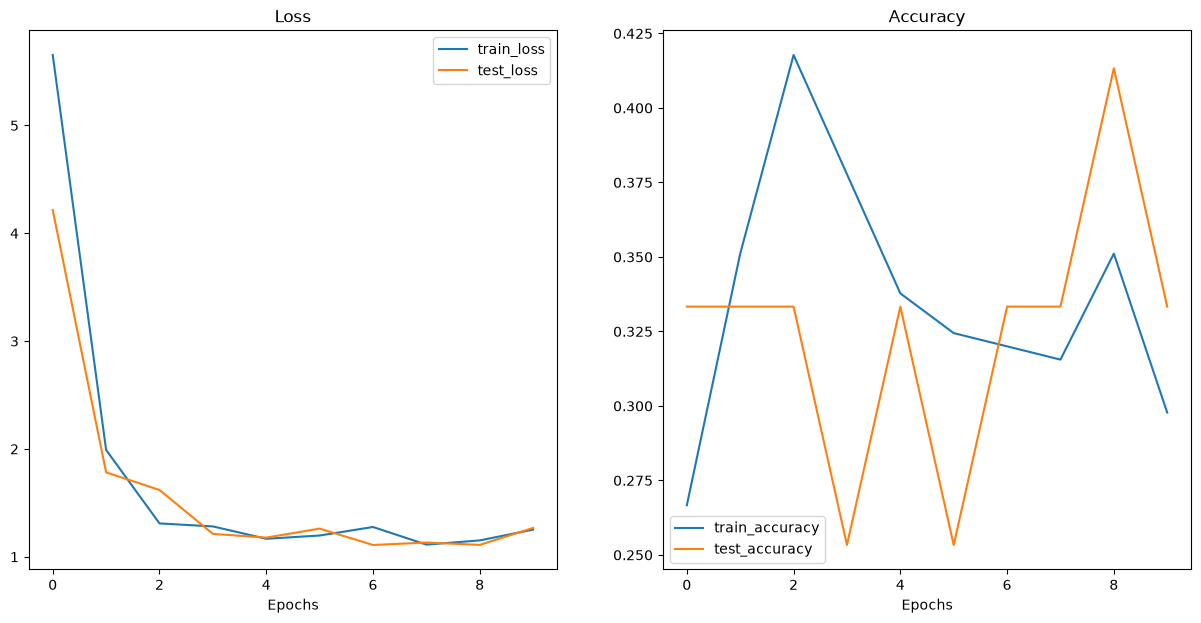

In [55]:
# 绘制模型的损失和准确率曲线
def plot_loss_curves(results):
    """根据训练结果字典绘制损失和准确率曲线。

    参数：
        results (dict): 包含各轮次指标列表的字典，例如：
            {"train_loss": [...],
             "train_acc": [...],
             "test_loss": [...],
             "test_acc": [...]}
    """
    loss = results["train_loss"]
    test_loss = results["test_loss"]

    accuracy = results["train_acc"]
    test_accuracy = results["test_acc"]

    epochs = range(len(results["train_loss"]))

    plt.figure(figsize=(15, 7))

    # 绘制损失曲线
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label="train_loss")
    plt.plot(epochs, test_loss, label="test_loss")
    plt.title("Loss")
    plt.xlabel("Epochs")
    plt.legend()

    # 绘制准确率曲线
    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, label="train_accuracy")
    plt.plot(epochs, test_accuracy, label="test_accuracy")
    plt.title("Accuracy")
    plt.xlabel("Epochs")
    plt.legend()

# 绘制手写 ViT 模型的训练曲线
plot_loss_curves(results)

嗯，看起来我们模型的损失曲线到处都是。

至少损失看起来朝着正确的方向发展，但准确度曲线并没有真正显示出太大的希望。

这些结果可能是因为我们的 ViT 模型与 ViT 论文的数据资源和训练机制存在差异。

看来我们的模型严重欠拟合（没有达到我们想要的结果）。

我们看看是否可以通过引入预训练的 ViT 模型来解决这个问题？

## 10. 在同一数据集上使用来自 `torchvision.models` 的预训练 ViT

由于我们现在已经从头训练了自己的 ViT 并取得了不太理想的结果，迁移学习（使用预训练模型）的好处真正显现出来了。

### 10.1 为什么使用预训练模型？

许多现代机器学习研究论文的一个重要说明是，许多结果是通过大型数据集和庞大的计算资源获得的。

在现代机器学习中，原始完全训练的 ViT 可能不会被视为“超大型”训练设置（模型在不断变得越来越大）。

阅读 ViT 论文第 4.2 节：

> Finally, the ViT-L/16 model pre-trained on the public ImageNet-21k dataset performs well on most datasets too, while taking fewer resources to pre-train: it could be trained using a standard cloud TPUv3 with 8 cores in approximately **30 days**.

截至 2022 年 7 月，在 Google Cloud 上租用 8 核 TPUv3（Tensor Processing Unit version 3）的价格为每小时 8 美元。

连续租用 30 天的费用为 **5,760 美元**。

这种成本（金钱和时间）对于一些较大的研究团队或企业可能是可行的，但对许多人来说则不然。

因此，通过像 [`torchvision.models`](https://pytorch.org/vision/stable/models.html) 这样的资源提供预训练模型可用，是一个巨大的优势。

### 10.2 获取预训练 ViT 模型并创建特征提取器

我们可以从 `torchvision.models` 获取预训练的 ViT 模型。

我们将从顶部开始，首先确保我们有正确版本的 `torch` 和 `torchvision`。

> **注意：** 以下代码需要 `torch` v0.12+ 和 `torchvision` v0.13+ 才能使用最新的 `torchvision` 模型权重 API。

In [56]:
# 以下代码需要 torch 1.12+ 和 torchvision 0.13+
import torch
import torchvision
print(torch.__version__)
print(torchvision.__version__)

2.9.1+cu126
0.24.1+cu126


然后我们将设置设备无关代码。

In [57]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

现在让我们获取预训练的 ViT-Base 权重，并关闭其参数的梯度。

In [58]:
# 1. 获取 ViT-Base 预训练权重
pretrained_vit_weights = torchvision.models.ViT_B_16_Weights.DEFAULT # 需要 torchvision >= 0.13，DEFAULT 表示默认推荐的预训练权重

# 2. 创建加载预训练权重的 ViT 模型
pretrained_vit = torchvision.models.vit_b_16(weights=pretrained_vit_weights).to(device)

# 3. 冻结主干网络参数
for parameter in pretrained_vit.parameters():
    parameter.requires_grad = False

# 4. 替换分类头，先设置随机种子以保持线性层初始化一致
set_seed()
pretrained_vit.heads = nn.Linear(in_features=768, out_features=len(class_names)).to(device)
# pretrained_vit # 取消注释可查看模型结构

现在让我们创建一个特征提取器模型。

In [59]:
# 使用 torchinfo 打印模型结构摘要
summary(model=pretrained_vit,
        input_size=(32, 3, 224, 224), # 维度：（批次大小，颜色通道数，高度，宽度）
        # col_names=["input_size"], # 取消注释可精简输出
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"]
)

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
VisionTransformer (VisionTransformer)                        [32, 3, 224, 224]    [32, 3]              768                  Partial
├─Conv2d (conv_proj)                                         [32, 3, 224, 224]    [32, 768, 14, 14]    (590,592)            False
├─Encoder (encoder)                                          [32, 197, 768]       [32, 197, 768]       151,296              False
│    └─Dropout (dropout)                                     [32, 197, 768]       [32, 197, 768]       --                   --
│    └─Sequential (layers)                                   [32, 197, 768]       [32, 197, 768]       --                   False
│    │    └─EncoderBlock (encoder_layer_0)                   [32, 197, 768]       [32, 197, 768]       (7,087,872)          False
│    │    └─EncoderBlock (encoder_layer_1)                   [32, 197, 768]       [32, 

我们可以通过检查可训练参数的数量来确认我们的模型是否设置正确。

现在我们已经有了一个特征提取器模型，让我们获取一些数据并准备 DataLoaders。

In [60]:
# 从 GitHub 下载 pizza、steak、sushi 图像数据集
image_path = download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                           destination="pizza_steak_sushi")
image_path

[INFO] 数据集已通过完整性检查：D:\project\image-classification-basics\data\pizza_steak_sushi
download_data 耗时: 0.49 秒


WindowsPath('D:/project/image-classification-basics/data/pizza_steak_sushi')

让我们设置训练和测试目录路径。

In [61]:
# 设置训练集和测试集目录
train_dir = image_path / "train"
test_dir = image_path / "test"
train_dir, test_dir

(WindowsPath('D:/project/image-classification-basics/data/pizza_steak_sushi/train'),
 WindowsPath('D:/project/image-classification-basics/data/pizza_steak_sushi/test'))

最后，我们将把图像转换为张量，并将张量转换为 DataLoaders。

由于我们使用的是来自 `torchvision.models` 的预训练模型，我们可以在其上调用 `transforms()` 方法以获取其所需的 transforms。

记住，如果你要使用预训练模型，通常重要的是**确保你自己的自定义数据以与原始模型训练数据相同的方式进行转换/格式化**。

我们在 [06. PyTorch Transfer Learning 第 2.2 节](https://www.learnpytorch.io/06_pytorch_transfer_learning/#22-creating-a-transform-for-torchvisionmodels-auto-creation) 中涵盖了这种“自动” transform 创建方法。

In [62]:
# 获取预训练 ViT 权重对应的预处理流程
pretrained_vit_transforms = pretrained_vit_weights.transforms()
print(pretrained_vit_transforms)

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


现在我们已经准备好了 transforms，我们可以使用我们在 [05. PyTorch Going Modular 第 2 节](https://www.learnpytorch.io/05_pytorch_going_modular/#2-create-datasets-and-dataloaders-data_setuppy) 中创建的 `data_setup.create_dataloaders()` 方法将图像转换为 DataLoaders。

由于我们使用的是特征提取器模型（可训练参数较少），我们可以将批量大小增加到更高的值（如果我们将其设置为 1024，我们将模仿 [*Better plain ViT baselines for ImageNet-1k*](https://arxiv.org/abs/2205.01580) 中发现的改进，该论文改进了原始 ViT 论文并建议额外阅读）。但由于我们总共只有约 200 个训练样本，我们将坚持使用 32。

In [63]:
# 创建数据加载器
train_dataloader_pretrained, test_dataloader_pretrained, class_names = create_dataloaders(train_dir=train_dir,
                                                                                                     test_dir=test_dir,
                                                                                                     transform=pretrained_vit_transforms,
                                                                                                     batch_size=32,
                                                                                                     num_workers=0) 

create_dataloaders 耗时: 0.04 秒


### 10.4 训练特征提取器 ViT 模型

特征提取器模型准备就绪，DataLoaders 准备就绪，是时候训练了！

像以前一样，我们将使用 Adam 优化器（`torch.optim.Adam()`），学习率为 `1e-3`，损失函数为 `torch.nn.CrossEntropyLoss()`。

我们在 [05. PyTorch Going Modular 第 4 节](https://www.learnpytorch.io/05_pytorch_going_modular/#4-creating-train_step-and-test_step-functions-and-train-to-combine-them) 中创建的 `engine.train()` 函数将处理其余部分。

In [64]:
# 创建优化器和损失函数
optimizer = torch.optim.Adam(params=pretrained_vit.parameters(),
                             lr=1e-3)
loss_fn = torch.nn.CrossEntropyLoss()

# 训练预训练 ViT 特征提取模型的分类头
set_seed()
pretrained_vit_results = train(model=pretrained_vit,
                                      train_loader=train_dataloader_pretrained,
                                      test_loader=test_dataloader_pretrained,
                                      optimizer=optimizer,
                                      loss_fn=loss_fn,
                                      epochs=10,
                                      device=device,
                                      save_dir='./runs/pretrained_vit')


训练轮次：1/10


评估: 100%|██████████| 3/3 [00:00<00:00,  4.50it/s]


训练准确率：0.6800 训练损失：0.8434 评估准确率：0.8933 评估损失：0.4971

训练轮次：2/10


评估: 100%|██████████| 3/3 [00:00<00:00,  4.68it/s]


训练准确率：0.9378 训练损失：0.3791 评估准确率：0.9200 评估损失：0.2861

训练轮次：3/10


...

训练准确率：0.9822 训练损失：0.0897 评估准确率：0.9333 评估损失：0.1822

训练轮次：9/10


评估: 100%|██████████| 3/3 [00:00<00:00,  4.47it/s]


训练准确率：0.9867 训练损失：0.0783 评估准确率：0.9467 评估损失：0.1755

训练轮次：10/10


评估: 100%|██████████| 3/3 [00:00<00:00,  4.70it/s]

训练准确率：0.9911 训练损失：0.0733 评估准确率：0.9200 评估损失：0.1811
train 耗时: 32.14 秒


看起来我们的预训练 ViT 特征提取器比我们从头训练的自定义 ViT 模型表现好得多（在其他配置相同的条件下）。

让我们可视化一下。

漂亮！那些是一些漂亮的损失曲线。

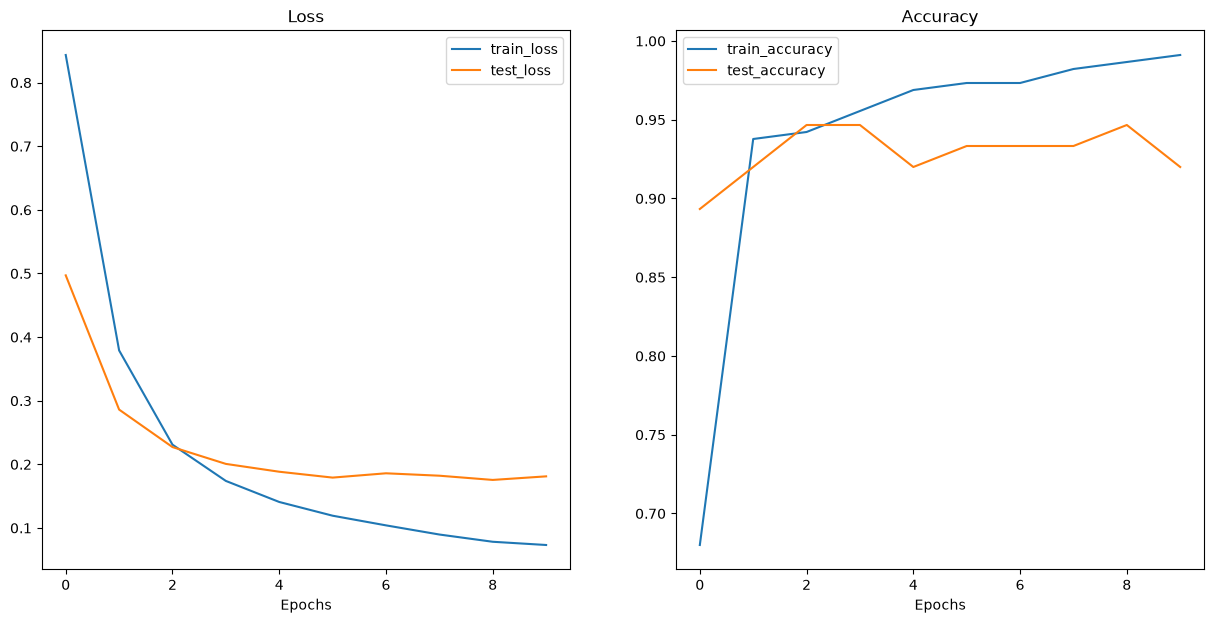

In [65]:
# 绘制训练曲线
plot_loss_curves(pretrained_vit_results)

### 10.5 保存特征提取器 ViT 模型

现在我们已经有了一个表现良好的 ViT 模型，我们可以将其保存以备后用。

（我们已经在 train() 函数的最后进行了模型保存。 保存为 `./runs/pretrained_vit/best.pt `）

## 11. 在自定义图像上进行预测

我们训练的模型在测试数据集上表现良好。

但是我们如何测试它在我们自己的自定义图像上的表现？

换句话说，如果我们有一张我们自己的披萨、牛排或寿司的照片，我们的模型会预测什么？

让我们找出答案。

为此，我们将下载著名的 pizza-dad 图像（一张我爸爸吃披萨的照片），并在其上使用我们的最佳表现模型进行预测。

In [66]:
from pathlib import Path

# 获取模型文件的字节数，并换算为 MB
pretrained_vit_model_size = Path("runs/pretrained_vit/best.pt").stat().st_size // (1024*1024) # 除以 1024 的平方，将字节换算为 MB
print(f"Pretrained ViT feature extractor model size: {pretrained_vit_model_size} MB")

Pretrained ViT feature extractor model size: 327 MB


现在我们已经有了图像，让我们进行预测并绘制结果。

披萨！我们的模型正确地将图像预测为披萨。

这就是机器学习的魔力，看到它在你自己的数据上工作。

In [67]:
from utils import download_image

# 设置自定义图像路径
custom_image_path = image_path / "04-pizza-dad.jpeg"

# 检查已有图像，并在缺失或损坏时重新下载。
download_image(
    source="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/04-pizza-dad.jpeg",
    destination=custom_image_path,
)


WindowsPath('D:/project/image-classification-basics/data/pizza_steak_sushi/04-pizza-dad.jpeg')

In [68]:
import torch
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

from typing import List, Tuple

from PIL import Image

def pred_and_plot_image(
    model: torch.nn.Module,
    class_names: List[str],
    image_path: str | Path,
    image_size: Tuple[int, int] = (224, 224),
    transform  =  None,
    device: str = device,
):
    """使用指定模型预测图像，并绘制预测结果。

    参数：
        model (torch.nn.Module): 用于预测图像的 PyTorch 模型。
        class_names (List[str]): 将预测类别编号映射到名称的列表。
        image_path (str | Path): 待预测图像的文件路径。
        image_size (Tuple[int, int]): 默认预处理的目标尺寸，默认为 (224, 224)。
        transform: 图像预处理流程；未传入时使用 ImageNet 归一化。
        device (str): 执行预测的设备，默认使用前面选定的设备。
    """

    # 打开图像并统一转换为 RGB
    with Image.open(image_path) as source:
        img = source.convert("RGB")

    # 如果没有传入预处理流程，则创建默认流程
    if transform is not None:
        image_transform = transform
    else:
        image_transform = transforms.Compose(
            [
                transforms.Resize(image_size),
                transforms.ToTensor(),
                transforms.Normalize(
                    mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
                ),
            ]
        )

    ### 对图像进行预测 ###

    # 确保模型位于指定设备
    model.to(device)

    # 切换为评估模式并启用推理模式
    model.eval()
    with torch.inference_mode():
        # 对图像进行预处理并添加批次维度，模型输入为 [batch_size, color_channels, height, width]
        transformed_image = image_transform(img).unsqueeze(dim=0)

        # 将带有批次维度的图像送入指定设备上的模型进行预测
        target_image_pred = model(transformed_image.to(device))

    # 使用 torch.softmax() 将多分类的 logits 转换为预测概率
    target_image_pred_probs = torch.softmax(target_image_pred, dim=1)

    # 将预测概率转换为类别编号
    target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1)

    # 绘制图像、预测类别和概率
    plt.figure()
    plt.imshow(img)
    plt.title(
        f"Pred: {class_names[target_image_pred_label]} | Prob: {target_image_pred_probs.max():.3f}"
    )
    plt.axis(False)

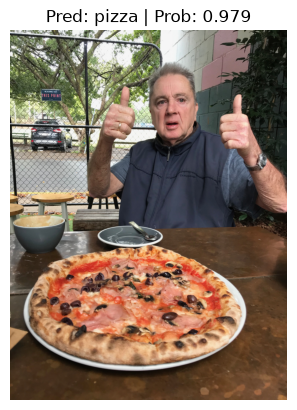

In [69]:
# 对自定义图像进行预测
pretrained_vit.load_state_dict(
    torch.load("runs/pretrained_vit/best.pt", map_location=device, weights_only=True)
)
pred_and_plot_image(model=pretrained_vit,
                    image_path=custom_image_path,
                    class_names=class_names,
                    transform=pretrained_vit_transforms,
                    device=device)

## 主要收获

* 论文复现是一项很有价值的技能，可以帮助你跟上机器学习研究的最新进展。
* 在复现论文时，最好从较小的部分开始，并逐步构建到更大的部分。
* 使用现有的 PyTorch 层可以节省大量时间，并且这些层通常经过高度优化和测试。
* 预训练模型可以是提高模型性能的强大工具，尤其是在数据有限时。

## 练习

1. 论文复现的主要目标是什么？
2. 为什么复现机器学习研究论文很有用？
3. 复现 ViT 论文时，论文中的哪些三个主要部分最有帮助？
4. ViT 架构中的“ patch  embedding”是什么？
5. 什么是多头注意力？它如何帮助 Transformer 模型？
6. 残差连接在 Transformer 架构中起什么作用？
7. 为什么在训练自定义 ViT 模型时使用较小的批量大小？
8. 使用预训练 ViT 模型与从头训练相比有什么好处？
9. 你如何确保自定义数据与预训练模型的训练数据以相同的方式进行转换？
10. 在你自己的自定义图像上测试模型时有哪些步骤？

## 课外资源

* 阅读原始 ViT 论文：[*An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale*](https://arxiv.org/abs/2010.11929)。
* 查看 [lucidrains 的 vit-pytorch 仓库](https://github.com/lucidrains/vit-pytorch) 以获取更多 ViT 实现。
* 阅读 [Attention is All You Need](https://arxiv.org/abs/1706.03762) 论文以了解原始 Transformer 架构。
* 探索 [Papers with Code](https://paperswithcode.com/) 以查找更多带有代码的机器学习论文。
* 尝试在更大的数据集上训练你的 ViT 模型，看看性能如何变化。
* 实验不同的超参数，例如学习率、批量大小和 epoch 数。
* 查看 [PyTorch 文档](https://pytorch.org/docs/stable/index.html) 以获取有关使用的层和函数的更多详细信息。